
# An Explainable Physics-Informed Digital Twin
## for Lithium-Ion Battery Health Monitoring

### Project Objective

This project aims to develop a lightweight,
physics-informed Digital Twin prototype for
monitoring lithium-ion battery degradation.

The framework combines:
- Experimental battery cycling data
- Battery health indicator extraction
- Equivalent-circuit modelling
- Machine learning-based SoH estimation
- Digital Twin state monitoring

### Dataset

NASA Lithium-Ion Battery Aging Dataset

Initial case study: Battery B0005

### Research Question

To what extent can physically interpretable
health indicators and equivalent-circuit modelling,
combined with lightweight machine learning,
improve the accuracy and interpretability of
State-of-Health monitoring in lithium-ion batteries?


In [1]:

# Check the Python environment

import sys

print("Python version:", sys.version)
print("Development environment: Google Colab")
print("Battery Digital Twin project initialized.")


Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Development environment: Google Colab
Battery Digital Twin project initialized.


In [2]:

# Import the libraries required for battery data analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import loadmat

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

from google.colab import files

uploaded = files.upload()


Saving B0005.mat to B0005.mat


In [4]:

# Load the NASA battery dataset

mat = loadmat(
    "B0005.mat",
    squeeze_me=True,
    struct_as_record=False
)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [5]:

# Identify the main variables stored in the MATLAB file

for key in mat.keys():
    if not key.startswith("__"):
        print(key)


B0005


In [6]:

# Access the main battery structure

battery = mat["B0005"]

# Display the available fields
print("Battery structure fields:")
print(battery._fieldnames)


Battery structure fields:
['cycle']


In [7]:

# Access the experimental cycle records

cycles = np.atleast_1d(battery.cycle)

print("Total number of experimental records:", len(cycles))


Total number of experimental records: 616


In [8]:

# Inspect the first experimental record

first_record = cycles[0]

print("Fields in the first record:")
print(first_record._fieldnames)


Fields in the first record:
['type', 'ambient_temperature', 'time', 'data']


In [9]:

# Inspect the metadata of the first experiment

print("Experiment type:", first_record.type)

print("Ambient temperature:",
      first_record.ambient_temperature)

print("Experiment time:",
      first_record.time)


Experiment type: charge
Ambient temperature: 24
Experiment time: [2.0080e+03 4.0000e+00 2.0000e+00 1.3000e+01 8.0000e+00 1.7921e+01]


In [10]:

# Inspect the internal structure of the experimental data

experiment_data = first_record.data

print("Fields inside experimental data:")
print(experiment_data._fieldnames)


Fields inside experimental data:
['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_charge', 'Voltage_charge', 'Time']


In [11]:

# Inspect the size and shape of each measurement

for field in experiment_data._fieldnames:
    values = getattr(experiment_data, field)

    print(
        field,
        "| Shape:", np.shape(values),
        "| Number of measurements:", np.size(values)
    )


Voltage_measured | Shape: (789,) | Number of measurements: 789
Current_measured | Shape: (789,) | Number of measurements: 789
Temperature_measured | Shape: (789,) | Number of measurements: 789
Current_charge | Shape: (789,) | Number of measurements: 789
Voltage_charge | Shape: (789,) | Number of measurements: 789
Time | Shape: (789,) | Number of measurements: 789


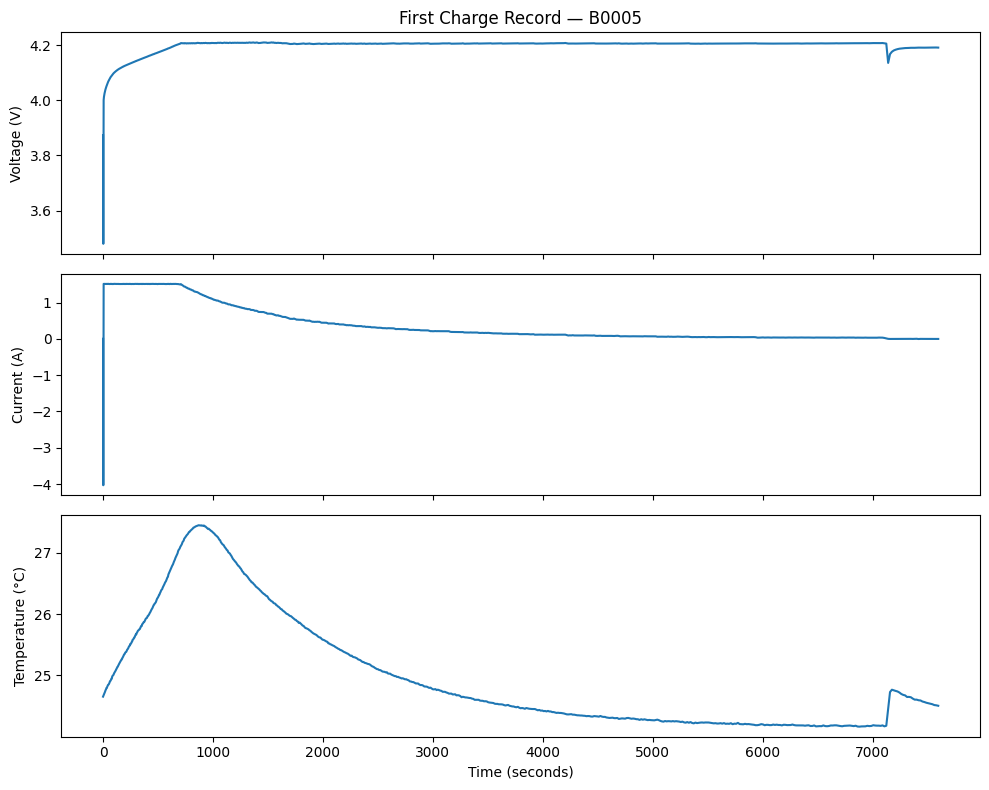

In [12]:
time = experiment_data.Time
voltage = experiment_data.Voltage_measured
current = experiment_data.Current_measured
temperature = experiment_data.Temperature_measured

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axes[0].plot(time, voltage)
axes[0].set_ylabel("Voltage (V)")
axes[0].set_title("First Charge Record — B0005")

axes[1].plot(time, current)
axes[1].set_ylabel("Current (A)")

axes[2].plot(time, temperature)
axes[2].set_ylabel("Temperature (°C)")
axes[2].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

In [13]:
from collections import Counter

record_types = [
    str(record.type) for record in cycles
]

type_counts = Counter(record_types)

for record_type, count in type_counts.items():
    print(f"{record_type}: {count}")

charge: 170
discharge: 168
impedance: 278


In [14]:
discharge_records = [
    record for record in cycles
    if str(record.type) == "discharge"
]

first_discharge = discharge_records[0]

print("Number of discharge records:", len(discharge_records))
print("Discharge data fields:")
print(first_discharge.data._fieldnames)

Number of discharge records: 168
Discharge data fields:
['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity']


In [15]:
discharge_data = first_discharge.data

for field in discharge_data._fieldnames:
    values = getattr(discharge_data, field)

    print(
        field,
        "| Shape:", np.shape(values),
        "| First 5 values:", np.asarray(values).flatten()[:5]
    )

Voltage_measured | Shape: (197,) | First 5 values: [4.19149181 4.19074907 3.97487091 3.95171671 3.93435249]
Current_measured | Shape: (197,) | First 5 values: [-4.90158921e-03 -1.47800555e-03 -2.01252832e+00 -2.01397936e+00
 -2.01114360e+00]
Temperature_measured | Shape: (197,) | First 5 values: [24.33003389 24.32599342 24.38908513 24.54475232 24.7313852 ]
Current_load | Shape: (197,) | First 5 values: [-6.0000e-04 -6.0000e-04 -1.9982e+00 -1.9982e+00 -1.9982e+00]
Voltage_load | Shape: (197,) | First 5 values: [0.    4.206 3.062 3.03  3.011]
Time | Shape: (197,) | First 5 values: [ 0.    16.781 35.703 53.781 71.922]
Capacity | Shape: () | First 5 values: [1.85648742]


In [16]:
capacity_values = np.array([
    float(record.data.Capacity)
    for record in discharge_records
])

print("Number of capacity measurements:", len(capacity_values))
print("First 10 capacity values:")
print(capacity_values[:10])

print("\nInitial capacity:", capacity_values[0], "Ah")
print("Minimum capacity:", capacity_values.min(), "Ah")
print("Maximum capacity:", capacity_values.max(), "Ah")

Number of capacity measurements: 168
First 10 capacity values:
[1.85648742 1.84632725 1.83534919 1.83526253 1.83464551 1.83566166
 1.83514614 1.82575679 1.82477385 1.82461327]

Initial capacity: 1.8564874208181574 Ah
Minimum capacity: 1.2874525221379407 Ah
Maximum capacity: 1.8564874208181574 Ah


In [17]:
initial_capacity = capacity_values[0]

soh_values = (capacity_values / initial_capacity) * 100

print("First 10 SoH values:")
print(np.round(soh_values[:10], 2))

print("\nInitial SoH:", round(soh_values[0], 2), "%")
print("Minimum SoH:", round(soh_values.min(), 2), "%")
print("Final SoH:", round(soh_values[-1], 2), "%")

First 10 SoH values:
[100.    99.45  98.86  98.86  98.82  98.88  98.85  98.34  98.29  98.28]

Initial SoH: 100.0 %
Minimum SoH: 69.35 %
Final SoH: 71.38 %


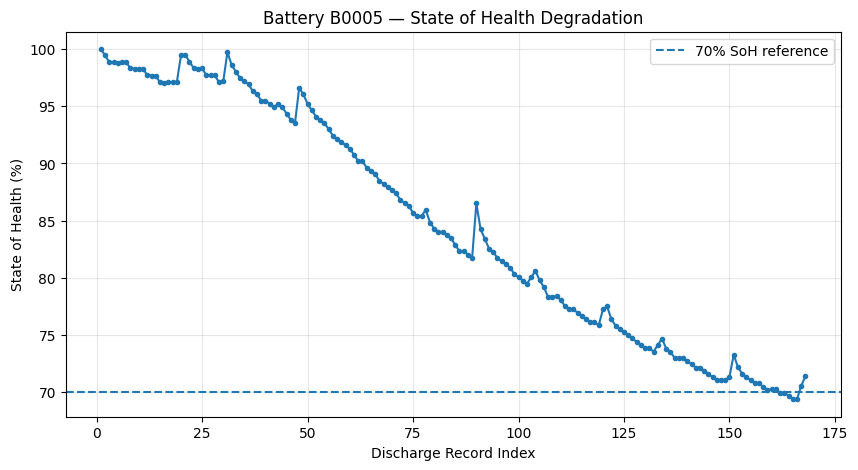

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(soh_values) + 1),
    soh_values,
    marker="o",
    markersize=3,
    linewidth=1.5
)

plt.axhline(
    y=70,
    linestyle="--",
    label="70% SoH reference"
)

plt.xlabel("Discharge Record Index")
plt.ylabel("State of Health (%)")
plt.title("Battery B0005 — State of Health Degradation")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [19]:
print("First discharge record:")
print("Date/time:", discharge_records[0].time)

print("\nLast discharge record:")
print("Date/time:", discharge_records[-1].time)

First discharge record:
Date/time: [2.0080e+03 4.0000e+00 2.0000e+00 1.5000e+01 2.5000e+01 4.1593e+01]

Last discharge record:
Date/time: [2008.       5.      27.      20.      45.      42.125]


In [20]:
from datetime import datetime

def convert_timestamp(timestamp):
    values = np.asarray(timestamp).flatten()
    return datetime(
        int(values[0]),
        int(values[1]),
        int(values[2]),
        int(values[3]),
        int(values[4]),
        int(values[5])
    )

timestamps = [
    convert_timestamp(record.time)
    for record in discharge_records
]

is_chronological = all(
    timestamps[i] <= timestamps[i + 1]
    for i in range(len(timestamps) - 1)
)

print("Records are chronologically ordered:", is_chronological)
print("First timestamp:", timestamps[0])
print("Last timestamp:", timestamps[-1])

Records are chronologically ordered: True
First timestamp: 2008-04-02 15:25:41
Last timestamp: 2008-05-27 20:45:42


In [21]:
battery_df = pd.DataFrame({
    "record_index": range(1, len(discharge_records) + 1),
    "timestamp": timestamps,
    "capacity_Ah": capacity_values,
    "SoH_percent": soh_values
})

print(battery_df.head(10))
print("\nDataset information:")
print(battery_df.info())

   record_index           timestamp  capacity_Ah  SoH_percent
0             1 2008-04-02 15:25:41     1.856487   100.000000
1             2 2008-04-02 19:43:48     1.846327    99.452721
2             3 2008-04-03 00:01:06     1.835349    98.861386
3             4 2008-04-03 04:16:37     1.835263    98.856718
4             5 2008-04-03 08:33:25     1.834646    98.823482
5             6 2008-04-03 12:55:10     1.835662    98.878217
6             7 2008-04-03 17:17:16     1.835146    98.850449
7             8 2008-04-03 21:28:14     1.825757    98.344690
8             9 2008-04-04 01:38:15     1.824774    98.291743
9            10 2008-04-04 05:48:08     1.824613    98.283094

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   record_index  168 non-null    int64         
 1   timestamp     168 non-null    datetim

In [22]:
print("Missing values:")
print(battery_df.isnull().sum())

print("\nDuplicated rows:")
print(battery_df.duplicated().sum())

print("\nStatistical summary:")
print(battery_df[["capacity_Ah", "SoH_percent"]].describe())

Missing values:
record_index    0
timestamp       0
capacity_Ah     0
SoH_percent     0
dtype: int64

Duplicated rows:
0

Statistical summary:
       capacity_Ah  SoH_percent
count   168.000000   168.000000
mean      1.572502    84.703082
std       0.190413    10.256615
min       1.287453    69.348842
25%       1.390021    74.873698
50%       1.557085    83.872664
75%       1.769163    95.296229
max       1.856487   100.000000


In [23]:
features = []

for i, record in enumerate(discharge_records):

    data = record.data

    voltage = np.asarray(data.Voltage_measured)
    current = np.asarray(data.Current_measured)
    temperature = np.asarray(data.Temperature_measured)
    time = np.asarray(data.Time)

    features.append({
        "record_index": i + 1,
        "voltage_mean": np.mean(voltage),
        "voltage_min": np.min(voltage),
        "voltage_max": np.max(voltage),
        "current_mean": np.mean(current),
        "temperature_mean": np.mean(temperature),
        "temperature_max": np.max(temperature),
        "discharge_duration_s": time[-1] - time[0]
    })

features_df = pd.DataFrame(features)

print(features_df.head())

   record_index  voltage_mean  voltage_min  voltage_max  current_mean  \
0             1      3.529829     2.612467     4.191492     -1.818702   
1             2      3.537320     2.587209     4.189773     -1.817560   
2             3      3.543737     2.651917     4.188187     -1.816487   
3             4      3.543666     2.592948     4.188461     -1.825589   
4             5      3.542343     2.547420     4.188299     -1.826114   

   temperature_mean  temperature_max  discharge_duration_s  
0         32.572328        38.982181              3690.234  
1         32.725235        39.033398              3672.344  
2         32.642862        38.818797              3651.641  
3         32.514876        38.762305              3631.563  
4         32.382349        38.665393              3629.172  


In [24]:
battery_analysis_df = battery_df.merge(
    features_df,
    on="record_index"
)

print("Dataset shape:", battery_analysis_df.shape)
print("\nColumns:")
print(battery_analysis_df.columns.tolist())

print("\nFirst five records:")
display(battery_analysis_df.head())

Dataset shape: (168, 11)

Columns:
['record_index', 'timestamp', 'capacity_Ah', 'SoH_percent', 'voltage_mean', 'voltage_min', 'voltage_max', 'current_mean', 'temperature_mean', 'temperature_max', 'discharge_duration_s']

First five records:


,record_index,timestamp,capacity_Ah,SoH_percent,voltage_mean,voltage_min,voltage_max,current_mean,temperature_mean,temperature_max,discharge_duration_s
0,1,2008-04-02 15:25:41,1.856487,100.000000,3.529829,2.612467,4.191492,-1.818702,32.572328,38.982181,3690.234
1,2,2008-04-02 19:43:48,1.846327,99.452721,3.537320,2.587209,4.189773,-1.817560,32.725235,39.033398,3672.344
2,3,2008-04-03 00:01:06,1.835349,98.861386,3.543737,2.651917,4.188187,-1.816487,32.642862,38.818797,3651.641
3,4,2008-04-03 04:16:37,1.835263,98.856718,3.543666,2.592948,4.188461,-1.825589,32.514876,38.762305,3631.563
4,5,2008-04-03 08:33:25,1.834646,98.823482,3.542343,2.547420,4.188299,-1.826114,32.382349,38.665393,3629.172


In [25]:
analysis_features = [
    "voltage_mean",
    "voltage_min",
    "voltage_max",
    "current_mean",
    "temperature_mean",
    "temperature_max",
    "discharge_duration_s"
]

pearson_corr = battery_analysis_df[
    analysis_features + ["SoH_percent"]
].corr(method="pearson")["SoH_percent"].drop("SoH_percent")

spearman_corr = battery_analysis_df[
    analysis_features + ["SoH_percent"]
].corr(method="spearman")["SoH_percent"].drop("SoH_percent")

correlation_df = pd.DataFrame({
    "Pearson": pearson_corr,
    "Spearman": spearman_corr
})

print(correlation_df.sort_values(
    by="Spearman",
    key=abs,
    ascending=False
))

                       Pearson  Spearman
discharge_duration_s  0.975523  0.997441
voltage_mean          0.982357  0.953624
current_mean         -0.933321 -0.895739
temperature_max      -0.935272 -0.890026
temperature_mean     -0.809744 -0.765751
voltage_min          -0.487071 -0.433499
voltage_max          -0.222038  0.021110


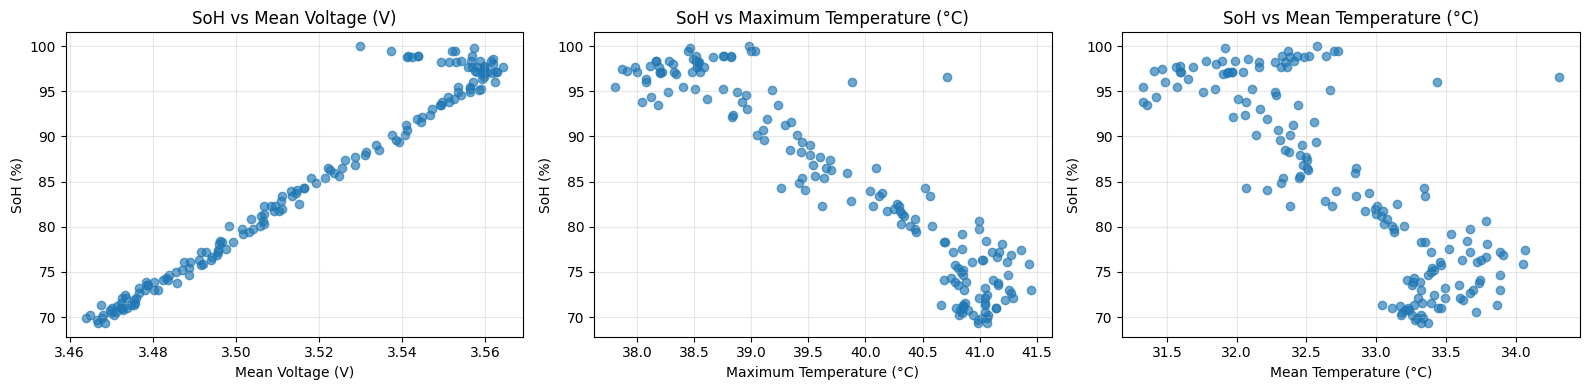

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

plots = [
    ("voltage_mean", "Mean Voltage (V)"),
    ("temperature_max", "Maximum Temperature (°C)"),
    ("temperature_mean", "Mean Temperature (°C)")
]

for ax, (column, label) in zip(axes, plots):
    ax.scatter(
        battery_analysis_df[column],
        battery_analysis_df["SoH_percent"],
        alpha=0.65
    )

    ax.set_xlabel(label)
    ax.set_ylabel("SoH (%)")
    ax.set_title(f"SoH vs {label}")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

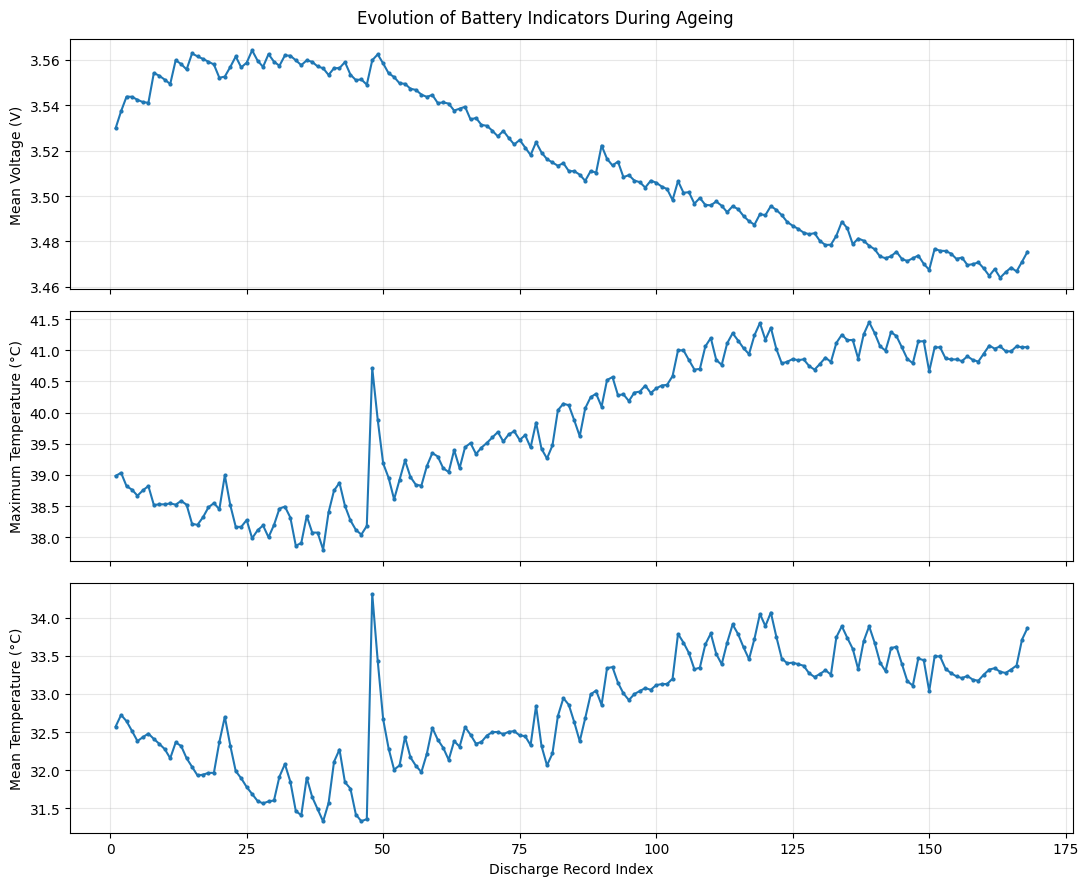

In [27]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

variables = [
    ("voltage_mean", "Mean Voltage (V)"),
    ("temperature_max", "Maximum Temperature (°C)"),
    ("temperature_mean", "Mean Temperature (°C)")
]

for ax, (column, label) in zip(axes, variables):

    ax.plot(
        battery_analysis_df["record_index"],
        battery_analysis_df[column],
        marker=".",
        markersize=4
    )

    ax.set_ylabel(label)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Discharge Record Index")

fig.suptitle("Evolution of Battery Indicators During Ageing")
plt.tight_layout()
plt.show()

In [28]:
for i in range(45, 52):

    record = discharge_records[i]
    data = record.data

    temperature = np.asarray(data.Temperature_measured)

    print(f"\nRecord {i+1}")
    print("Timestamp:", convert_timestamp(record.time))
    print("Ambient temperature:", record.ambient_temperature)
    print("Capacity:", record.data.Capacity)
    print("Temperature mean:", np.mean(temperature))
    print("Temperature min:", np.min(temperature))
    print("Temperature max:", np.max(temperature))


Record 46
Timestamp: 2008-04-26 05:57:35
Ambient temperature: 24
Capacity: 1.7418496047960008
Temperature mean: 31.331626572312267
Temperature min: 23.236214188565974
Temperature max: 38.04152715355532

Record 47
Timestamp: 2008-04-26 10:58:25
Ambient temperature: 24
Capacity: 1.7360913511847138
Temperature mean: 31.35934131425137
Temperature min: 23.214801785728056
Temperature max: 38.17980302242767

Record 48
Timestamp: 2008-04-29 12:15:56
Ambient temperature: 24
Capacity: 1.7936240148573608
Temperature mean: 34.31088483888259
Temperature min: 26.647373946169793
Temperature max: 40.71218198711114

Record 49
Timestamp: 2008-04-29 17:05:27
Ambient temperature: 24
Capacity: 1.7831890223273275
Temperature mean: 33.43585640373788
Temperature min: 25.69911743242072
Temperature max: 39.885261233152924

Record 50
Timestamp: 2008-04-29 22:00:04
Ambient temperature: 24
Capacity: 1.7673642076278957
Temperature mean: 32.66698125020078
Temperature min: 24.833281081823134
Temperature max: 39.1828

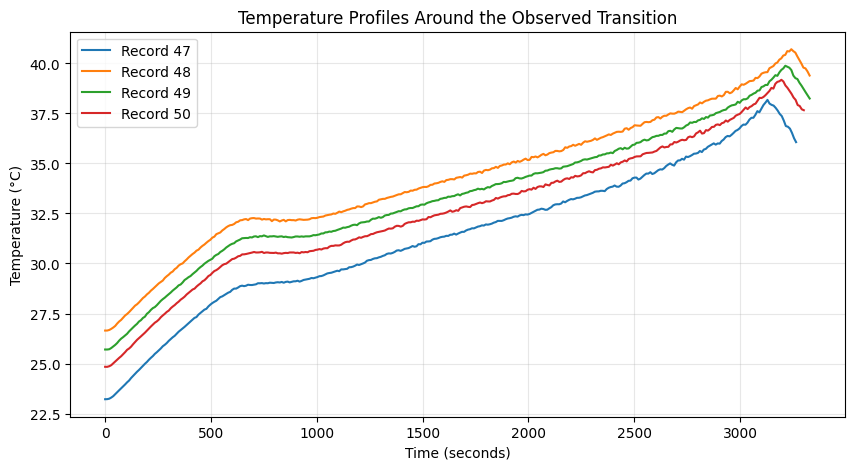

In [29]:
plt.figure(figsize=(10, 5))

for i in [46, 47, 48, 49]:
    data = discharge_records[i].data

    plt.plot(
        data.Time,
        data.Temperature_measured,
        label=f"Record {i+1}"
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Temperature (°C)")
plt.title("Temperature Profiles Around the Observed Transition")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [30]:
battery_analysis_df["temperature_rise"] = (
    battery_analysis_df["temperature_max"]
    - battery_analysis_df["temperature_mean"]
)

In [31]:
battery_analysis_df["temperature_rise"] = [
    np.max(record.data.Temperature_measured)
    - np.min(record.data.Temperature_measured)
    for record in discharge_records
]

print(
    battery_analysis_df[
        ["record_index", "SoH_percent", "temperature_mean",
         "temperature_max", "temperature_rise"]
    ].head(10)
)

   record_index  SoH_percent  temperature_mean  temperature_max  \
0             1   100.000000         32.572328        38.982181   
1             2    99.452721         32.725235        39.033398   
2             3    98.861386         32.642862        38.818797   
3             4    98.856718         32.514876        38.762305   
4             5    98.823482         32.382349        38.665393   
5             6    98.878217         32.434182        38.751695   
6             7    98.850449         32.480416        38.820701   
7             8    98.344690         32.410462        38.517130   
8             9    98.291743         32.346141        38.526268   
9            10    98.283094         32.276798        38.526981   

   temperature_rise  
0         14.656188  
1         14.347450  
2         14.084531  
3         14.110061  
4         14.146692  
5         14.237268  
6         14.245120  
7         13.805806  
8         13.897781  
9         13.965421  


In [32]:
temperature_correlations = battery_analysis_df[
    ["temperature_mean", "temperature_max",
     "temperature_rise", "SoH_percent"]
].corr(method="pearson")["SoH_percent"]

temperature_spearman = battery_analysis_df[
    ["temperature_mean", "temperature_max",
     "temperature_rise", "SoH_percent"]
].corr(method="spearman")["SoH_percent"]

print(pd.DataFrame({
    "Pearson": temperature_correlations.drop("SoH_percent"),
    "Spearman": temperature_spearman.drop("SoH_percent")
}))

                   Pearson  Spearman
temperature_mean -0.809744 -0.765751
temperature_max  -0.935272 -0.890026
temperature_rise -0.979129 -0.970110


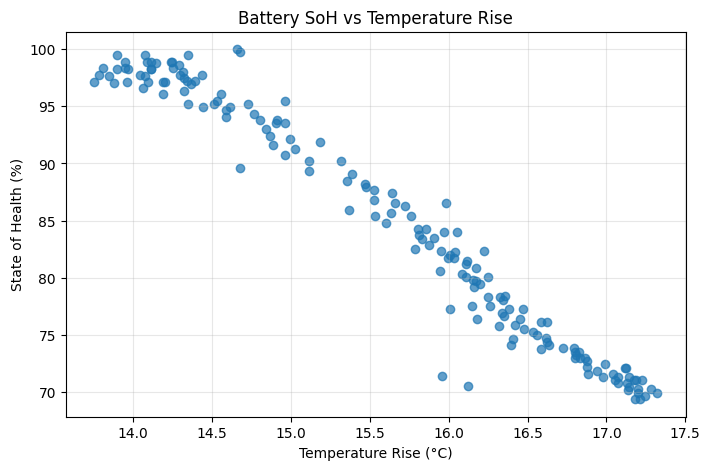

In [33]:
plt.figure(figsize=(8, 5))

plt.scatter(
    battery_analysis_df["temperature_rise"],
    battery_analysis_df["SoH_percent"],
    alpha=0.7
)

plt.xlabel("Temperature Rise (°C)")
plt.ylabel("State of Health (%)")
plt.title("Battery SoH vs Temperature Rise")
plt.grid(alpha=0.3)

plt.show()

In [34]:
temperature_outliers = battery_analysis_df[
    (battery_analysis_df["temperature_rise"] > 15.8) &
    (battery_analysis_df["SoH_percent"] < 75)
]

print(
    temperature_outliers[
        ["record_index", "SoH_percent",
         "temperature_rise", "temperature_mean",
         "temperature_max"]
    ].to_string(index=False)
)

 record_index  SoH_percent  temperature_rise  temperature_mean  temperature_max
          126    74.941784         16.562229         33.389849        40.839877
          127    74.669440         16.614737         33.370043        40.853761
          128    74.357448         16.624455         33.272160        40.747952
          129    74.077335         16.634934         33.222444        40.687940
          130    73.822897         16.722993         33.262077        40.781075
          131    73.822669         16.795206         33.312030        40.881593
          132    73.511703         16.803726         33.252879        40.811915
          133    74.085717         16.398390         33.745054        41.117935
          134    74.663125         16.405715         33.888420        41.248795
          135    73.787196         16.585849         33.735376        41.162430
          136    73.514250         16.824089         33.591311        41.164376
          137    72.950780         16.83

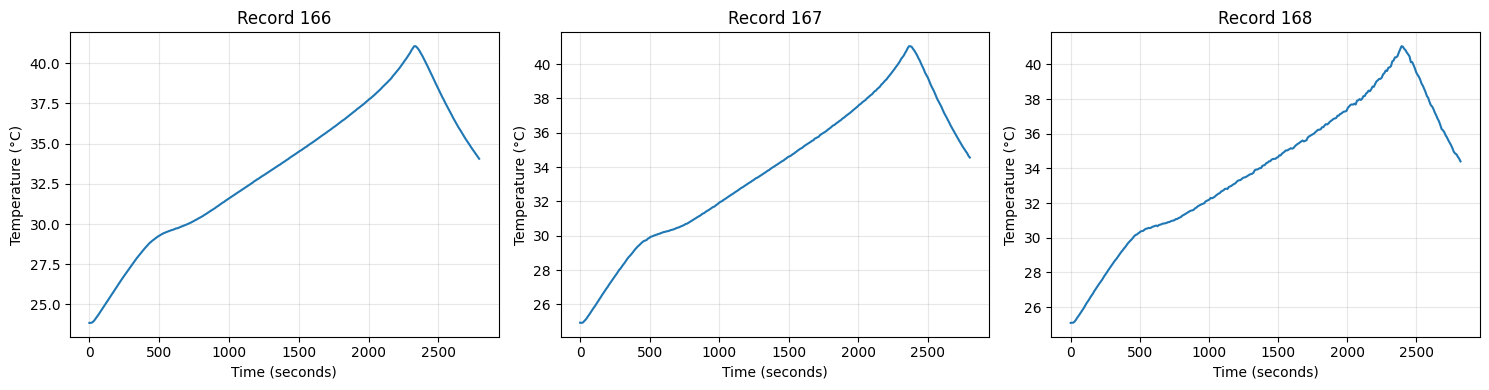

In [35]:
records_to_compare = [165, 166, 167]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, i in zip(axes, records_to_compare):

    data = discharge_records[i].data

    ax.plot(data.Time, data.Temperature_measured)

    ax.set_title(f"Record {i+1}")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Temperature (°C)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
battery_analysis_df.to_csv(
    "B0005_initial_feature_dataset.csv",
    index=False
)

print("Dataset saved successfully.")
print("Shape:", battery_analysis_df.shape)

Dataset saved successfully.
Shape: (168, 12)


In [37]:
impedance_records = [
    record for record in cycles
    if str(record.type) == "impedance"
]

print("Number of impedance records:", len(impedance_records))

first_impedance = impedance_records[0]

print("\nImpedance record fields:")
print(first_impedance._fieldnames)

print("\nImpedance data fields:")
print(first_impedance.data._fieldnames)

Number of impedance records: 278

Impedance record fields:
['type', 'ambient_temperature', 'time', 'data']

Impedance data fields:
['Sense_current', 'Battery_current', 'Current_ratio', 'Battery_impedance', 'Rectified_Impedance', 'Re', 'Rct']


In [38]:
impedance_data = first_impedance.data

for field in impedance_data._fieldnames:
    values = getattr(impedance_data, field)

    print(
        field,
        "| Shape:", np.shape(values),
        "| Data type:", np.asarray(values).dtype,
        "| First 5 values:", np.asarray(values).flatten()[:5]
    )

Sense_current | Shape: (48,) | Data type: complex128 | First 5 values: [ -1.         +1.j         820.60949707-36.23455048j
 827.2421875 -48.23122787j 827.19348145-56.19571686j
 824.92950439-53.24147797j]
Battery_current | Shape: (48,) | Data type: complex128 | First 5 values: [ -1.         +1.j         337.09146118-82.92077637j
 330.63156128-70.01371765j 330.80862427-61.73442459j
 332.68267822-57.62901306j]
Current_ratio | Shape: (48,) | Data type: complex128 | First 5 values: [1.        +0.j         2.32041452+0.46330459j 2.42419265+0.36746495j
 2.44700217+0.28677775j 2.43430498+0.26164607j]
Battery_impedance | Shape: (48,) | Data type: complex128 | First 5 values: [-0.43892625-0.1072983j   0.13008841-0.19711481j  0.05877056+0.03330657j
  0.00581351-0.06054655j  0.12608107-0.09044391j]
Rectified_Impedance | Shape: (39,) | Data type: complex128 | First 5 values: [0.07006938-4.79984691e-04j 0.06817886-1.19004093e-03j
 0.06793258-5.68268119e-05j 0.06691839-8.78726402e-04j
 0.06807105-1.

In [39]:
impedance_data_list = []

for i, record in enumerate(impedance_records):

    data = record.data

    impedance_data_list.append({
        "impedance_index": i + 1,
        "timestamp": convert_timestamp(record.time),
        "Re": float(data.Re),
        "Rct": float(data.Rct)
    })

impedance_df = pd.DataFrame(impedance_data_list)

print("Dataset shape:", impedance_df.shape)
print("\nFirst 10 records:")
display(impedance_df.head(10))

print("\nStatistical summary:")
display(impedance_df[["Re", "Rct"]].describe())

Dataset shape: (278, 4)

First 10 records:


,impedance_index,timestamp,Re,Rct
0,1,2008-04-18 20:55:29,0.044669,0.069456
1,2,2008-04-18 22:39:16,0.046687,0.076275
2,3,2008-04-19 02:14:27,0.044843,0.067972
3,4,2008-04-19 03:57:24,0.046195,0.074534
4,5,2008-04-19 07:32:33,0.045101,0.068528
5,6,2008-04-19 09:15:10,0.045991,0.073427
6,7,2008-04-19 12:47:00,0.044172,0.068044
7,8,2008-04-19 14:28:58,0.045217,0.074648
8,9,2008-04-19 18:12:47,0.043787,0.068450
9,10,2008-04-19 19:55:05,0.044910,0.073957



Statistical summary:


,Re,Rct
count,278.000000,278.000000
mean,0.054245,0.077340
std,0.005490,0.006367
min,0.043559,0.064883
25%,0.049161,0.071511
50%,0.055850,0.077487
75%,0.058815,0.082563
max,0.063516,0.089757


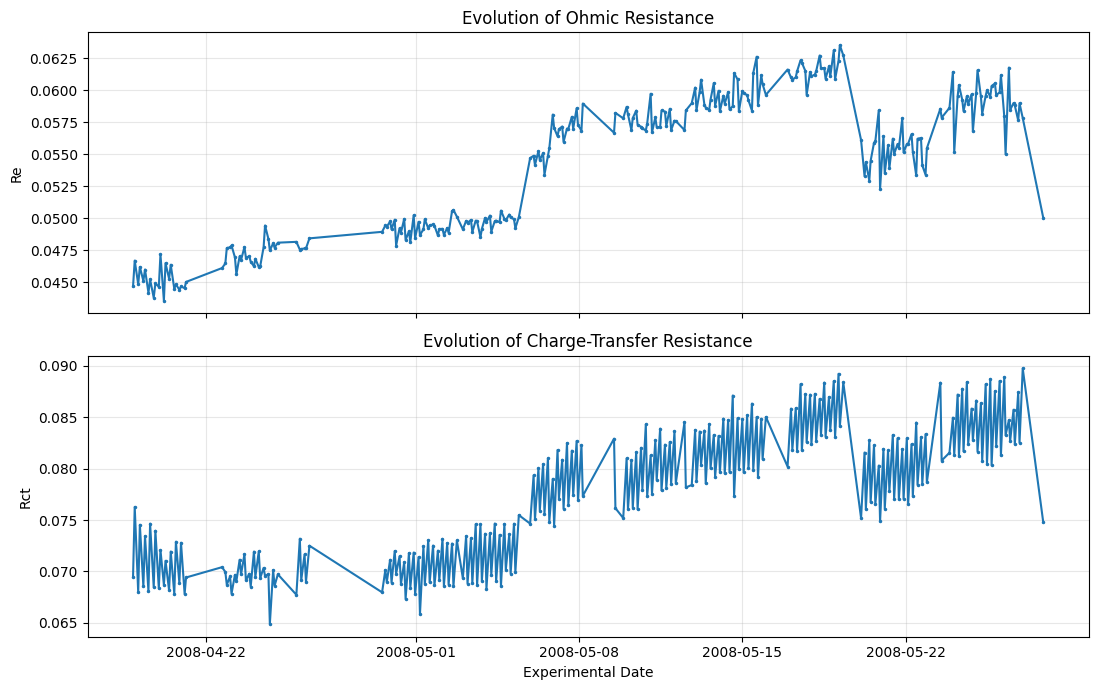

In [40]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(
    impedance_df["timestamp"],
    impedance_df["Re"],
    marker=".",
    markersize=3
)
axes[0].set_ylabel("Re")
axes[0].set_title("Evolution of Ohmic Resistance")
axes[0].grid(alpha=0.3)

axes[1].plot(
    impedance_df["timestamp"],
    impedance_df["Rct"],
    marker=".",
    markersize=3
)
axes[1].set_ylabel("Rct")
axes[1].set_title("Evolution of Charge-Transfer Resistance")
axes[1].set_xlabel("Experimental Date")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [41]:
impedance_df["time_difference_hours"] = (
    impedance_df["timestamp"].diff().dt.total_seconds() / 3600
)

print("Time difference statistics (hours):")
print(impedance_df["time_difference_hours"].describe())

print("\nLargest time gaps:")
display(
    impedance_df.nlargest(
        10, "time_difference_hours"
    )[["timestamp", "time_difference_hours", "Re", "Rct"]]
)

Time difference statistics (hours):
count    277.000000
mean       3.381407
std        5.700219
min        1.341111
25%        1.406944
50%        3.335000
75%        3.530556
max       74.771667
Name: time_difference_hours, dtype: float64

Largest time gaps:


,timestamp,time_difference_hours,Re,Rct
52,2008-04-29 13:12:54,74.771667,0.048934,0.067960
22,2008-04-22 16:33:03,37.101389,0.046106,0.070411
131,2008-05-09 11:53:10,32.116944,0.056672,0.082916
190,2008-05-16 22:28:31,22.316111,0.061607,0.080201
277,2008-05-27 21:34:28,21.109167,0.050036,0.074792
46,2008-04-25 21:00:31,19.056667,0.048151,0.067722
214,2008-05-20 02:06:32,18.288889,0.056099,0.075180
243,2008-05-23 11:41:10,13.875278,0.058545,0.088369
108,2008-05-05 21:33:38,11.644444,0.054692,0.074646
156,2008-05-12 12:24:36,8.933889,0.056877,0.084536


In [42]:
long_gaps = impedance_df[
    impedance_df["time_difference_hours"] > 6
]

print("Number of gaps greater than 6 hours:",
      len(long_gaps))

print("\nLong gaps:")
display(
    long_gaps[
        ["timestamp", "time_difference_hours", "Re", "Rct"]
    ]
)

Number of gaps greater than 6 hours: 14

Long gaps:


,timestamp,time_difference_hours,Re,Rct
22,2008-04-22 16:33:03,37.101389,0.046106,0.070411
46,2008-04-25 21:00:31,19.056667,0.048151,0.067722
52,2008-04-29 13:12:54,74.771667,0.048934,0.067960
84,2008-05-03 00:18:59,6.132222,0.049132,0.069330
108,2008-05-05 21:33:38,11.644444,0.054692,0.074646
131,2008-05-09 11:53:10,32.116944,0.056672,0.082916
133,2008-05-09 21:21:03,8.024444,0.057798,0.075190
156,2008-05-12 12:24:36,8.933889,0.056877,0.084536
158,2008-05-12 19:51:52,6.059167,0.058983,0.078409
190,2008-05-16 22:28:31,22.316111,0.061607,0.080201


In [43]:
discharge_time_df = battery_analysis_df[
    ["timestamp", "record_index", "SoH_percent"]
].rename(columns={"timestamp": "discharge_timestamp"})

impedance_time_df = impedance_df.copy()

matched_df = pd.merge_asof(
    impedance_time_df.sort_values("timestamp"),
    discharge_time_df.sort_values("discharge_timestamp"),
    left_on="timestamp",
    right_on="discharge_timestamp",
    direction="nearest"
)

matched_df["time_difference_hours"] = (
    matched_df["timestamp"] -
    matched_df["discharge_timestamp"]
).abs().dt.total_seconds() / 3600

print("Matching time-difference statistics:")
print(matched_df["time_difference_hours"].describe())

print("\nFirst 10 matches:")
display(matched_df.head(10))

Matching time-difference statistics:
count    278.000000
mean       0.774689
std        0.487525
min        0.245000
25%        0.532569
50%        0.810417
75%        0.878819
max        4.368056
Name: time_difference_hours, dtype: float64

First 10 matches:


,impedance_index,timestamp,Re,Rct,time_difference_hours,discharge_timestamp,record_index,SoH_percent
0,1,2008-04-18 20:55:29,0.044669,0.069456,0.247222,2008-04-18 21:10:19,20,99.490359
1,2,2008-04-18 22:39:16,0.046687,0.076275,1.482500,2008-04-18 21:10:19,20,99.490359
2,3,2008-04-19 02:14:27,0.044843,0.067972,0.245000,2008-04-19 02:29:09,21,99.511437
3,4,2008-04-19 03:57:24,0.046195,0.074534,1.470833,2008-04-19 02:29:09,21,99.511437
4,5,2008-04-19 07:32:33,0.045101,0.068528,0.245000,2008-04-19 07:47:15,22,98.905999
5,6,2008-04-19 09:15:10,0.045991,0.073427,1.465278,2008-04-19 07:47:15,22,98.905999
6,7,2008-04-19 12:47:00,0.044172,0.068044,0.245000,2008-04-19 13:01:42,23,98.345980
7,8,2008-04-19 14:28:58,0.045217,0.074648,1.454444,2008-04-19 13:01:42,23,98.345980
8,9,2008-04-19 18:12:47,0.043787,0.068450,0.245000,2008-04-19 18:27:29,24,98.310046
9,10,2008-04-19 19:55:05,0.044910,0.073957,1.460000,2008-04-19 18:27:29,24,98.310046


In [44]:
print("Total impedance records:", len(matched_df))

print(
    "Unique discharge records matched:",
    matched_df["record_index"].nunique()
)

print(
    "Impedance records per discharge record:"
)

print(
    matched_df["record_index"]
    .value_counts()
    .value_counts()
    .sort_index()
)

Total impedance records: 278
Unique discharge records matched: 144
Impedance records per discharge record:
count
1     14
2    126
3      4
Name: count, dtype: int64


In [45]:
impedance_aggregated = (
    matched_df
    .groupby("record_index")
    .agg(
        Re_mean=("Re", "mean"),
        Rct_mean=("Rct", "mean"),
        impedance_count=("impedance_index", "count")
    )
    .reset_index()
)

print("Aggregated dataset shape:",
      impedance_aggregated.shape)

display(impedance_aggregated.head(10))

Aggregated dataset shape: (144, 4)


,record_index,Re_mean,Rct_mean,impedance_count
0,20,0.045678,0.072866,2
1,21,0.045519,0.071253,2
2,22,0.045546,0.070977,2
3,23,0.044695,0.071346,2
4,24,0.044348,0.071204,2
5,25,0.045905,0.070211,2
6,26,0.045024,0.069856,2
7,27,0.045814,0.070037,2
8,28,0.044656,0.070357,2
9,29,0.044539,0.070822,2


In [46]:
battery_impedance_df = battery_analysis_df.merge(
    impedance_aggregated,
    on="record_index",
    how="left"
)

print("Final dataset shape:", battery_impedance_df.shape)

print(
    "Records with impedance data:",
    battery_impedance_df["Re_mean"].notna().sum()
)

Final dataset shape: (168, 15)
Records with impedance data: 144


In [47]:
matched_df["signed_offset_hours"] = (
    matched_df["timestamp"] -
    matched_df["discharge_timestamp"]
).dt.total_seconds() / 3600

print("Signed temporal offset (hours):")
print(matched_df["signed_offset_hours"].describe())

print("\nTemporal relationship:")
print(
    "Impedance before discharge:",
    (matched_df["signed_offset_hours"] < 0).sum()
)

print(
    "Impedance after discharge:",
    (matched_df["signed_offset_hours"] > 0).sum()
)

print(
    "Same timestamp:",
    (matched_df["signed_offset_hours"] == 0).sum()
)

Signed temporal offset (hours):
count    278.000000
mean       0.275816
std        0.873866
min       -1.775833
25%       -0.532500
50%        0.808194
75%        0.876458
max        4.368056
Name: signed_offset_hours, dtype: float64

Temporal relationship:
Impedance before discharge: 133
Impedance after discharge: 145
Same timestamp: 0


In [48]:
past_only_df = pd.merge_asof(
    discharge_time_df.sort_values("discharge_timestamp"),
    impedance_time_df.sort_values("timestamp"),
    left_on="discharge_timestamp",
    right_on="timestamp",
    direction="backward"
)

past_only_df["impedance_age_hours"] = (
    past_only_df["discharge_timestamp"]
    - past_only_df["timestamp"]
).dt.total_seconds() / 3600

print("Discharge records:", len(past_only_df))

print(
    "Records with a previous impedance measurement:",
    past_only_df["Re"].notna().sum()
)

print("\nAge of previous impedance measurement (hours):")
print(past_only_df["impedance_age_hours"].describe())

Discharge records: 168
Records with a previous impedance measurement: 149

Age of previous impedance measurement (hours):
count    149.000000
mean       2.384855
std        7.613164
min        0.245000
25%        0.530833
50%        0.532778
75%        0.534722
max       73.822222
Name: impedance_age_hours, dtype: float64


In [49]:
tolerances = [1, 2, 6]

print("Matching tolerance analysis")
print("----------------------------")

for hours in tolerances:
    valid_matches = (
        past_only_df["impedance_age_hours"] <= hours
    ).sum()

    print(
        f"Tolerance: {hours} hours | "
        f"Valid matches: {valid_matches} / 168"
    )

Matching tolerance analysis
----------------------------
Tolerance: 1 hours | Valid matches: 132 / 168
Tolerance: 2 hours | Valid matches: 133 / 168
Tolerance: 6 hours | Valid matches: 135 / 168


In [50]:
# Keep only impedance measurements within 1 hour
battery_impedance_final = past_only_df[
    past_only_df["impedance_age_hours"] <= 1
].copy()

# Keep the relevant impedance features
battery_impedance_final = battery_impedance_final[
    [
        "record_index",
        "Re",
        "Rct",
        "impedance_age_hours"
    ]
]

# Merge with the battery health indicators
final_df = battery_analysis_df.merge(
    battery_impedance_final,
    on="record_index",
    how="left"
)

print("Final dataset shape:", final_df.shape)
print("Matched impedance records:", final_df["Re"].notna().sum())
print("Missing impedance records:", final_df["Re"].isna().sum())

final_df.head()

Final dataset shape: (168, 15)
Matched impedance records: 132
Missing impedance records: 36


,record_index,timestamp,capacity_Ah,SoH_percent,voltage_mean,voltage_min,voltage_max,current_mean,temperature_mean,temperature_max,discharge_duration_s,temperature_rise,Re,Rct,impedance_age_hours
0,1,2008-04-02 15:25:41,1.856487,100.000000,3.529829,2.612467,4.191492,-1.818702,32.572328,38.982181,3690.234,14.656188,NaN,NaN,NaN
1,2,2008-04-02 19:43:48,1.846327,99.452721,3.537320,2.587209,4.189773,-1.817560,32.725235,39.033398,3672.344,14.347450,NaN,NaN,NaN
2,3,2008-04-03 00:01:06,1.835349,98.861386,3.543737,2.651917,4.188187,-1.816487,32.642862,38.818797,3651.641,14.084531,NaN,NaN,NaN
3,4,2008-04-03 04:16:37,1.835263,98.856718,3.543666,2.592948,4.188461,-1.825589,32.514876,38.762305,3631.563,14.110061,NaN,NaN,NaN
4,5,2008-04-03 08:33:25,1.834646,98.823482,3.542343,2.547420,4.188299,-1.826114,32.382349,38.665393,3629.172,14.146692,NaN,NaN,NaN


In [51]:
# Identify cycles with and without impedance measurements
final_df["impedance_available"] = final_df["Re"].notna()

# Summarise availability
availability_summary = (
    final_df.groupby("impedance_available")
    .agg(
        number_of_cycles=("record_index", "count"),
        mean_SoH=("SoH_percent", "mean"),
        min_SoH=("SoH_percent", "min"),
        max_SoH=("SoH_percent", "max")
    )
)

availability_summary

,number_of_cycles,mean_SoH,min_SoH,max_SoH
impedance_available,,,,
False,36,90.830914,70.510328,100.000000
True,132,83.031855,69.348842,99.511437


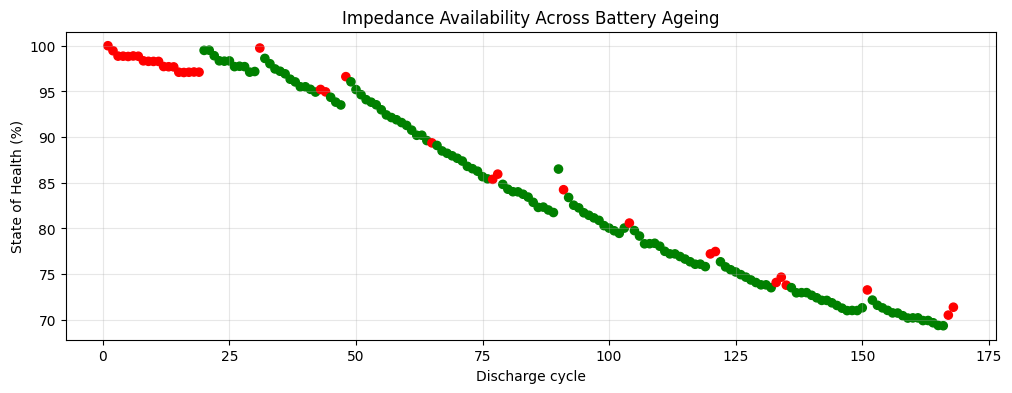

In [52]:
plt.figure(figsize=(12, 4))

plt.scatter(
    final_df["record_index"],
    final_df["SoH_percent"],
    c=final_df["impedance_available"].map({
        True: "green",
        False: "red"
    }),
    s=35
)

plt.xlabel("Discharge cycle")
plt.ylabel("State of Health (%)")
plt.title("Impedance Availability Across Battery Ageing")
plt.grid(alpha=0.3)

plt.show()

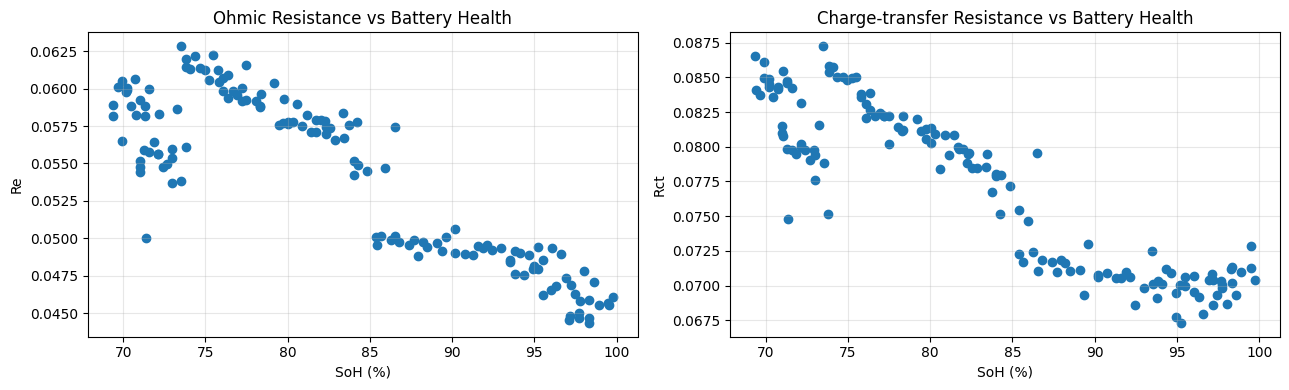

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].scatter(
    battery_impedance_df["SoH_percent"],
    battery_impedance_df["Re_mean"]
)
axes[0].set_xlabel("SoH (%)")
axes[0].set_ylabel("Re")
axes[0].set_title("Ohmic Resistance vs Battery Health")
axes[0].grid(alpha=0.3)

axes[1].scatter(
    battery_impedance_df["SoH_percent"],
    battery_impedance_df["Rct_mean"]
)
axes[1].set_xlabel("SoH (%)")
axes[1].set_ylabel("Rct")
axes[1].set_title("Charge-transfer Resistance vs Battery Health")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [54]:
from scipy.stats import pearsonr, spearmanr

impedance_valid = battery_impedance_df.dropna(
    subset=["Re_mean", "Rct_mean"]
)

for feature in ["Re_mean", "Rct_mean"]:
    pearson_corr, pearson_p = pearsonr(
        impedance_valid[feature],
        impedance_valid["SoH_percent"]
    )

    spearman_corr, spearman_p = spearmanr(
        impedance_valid[feature],
        impedance_valid["SoH_percent"]
    )

    print(f"\n{feature}")
    print(f"Pearson correlation:  {pearson_corr:.4f} (p={pearson_p:.4g})")
    print(f"Spearman correlation: {spearman_corr:.4f} (p={spearman_p:.4g})")


Re_mean
Pearson correlation:  -0.8677 (p=6.035e-45)
Spearman correlation: -0.8058 (p=3.983e-34)

Rct_mean
Pearson correlation:  -0.9055 (p=1.003e-54)
Spearman correlation: -0.8690 (p=3.14e-45)


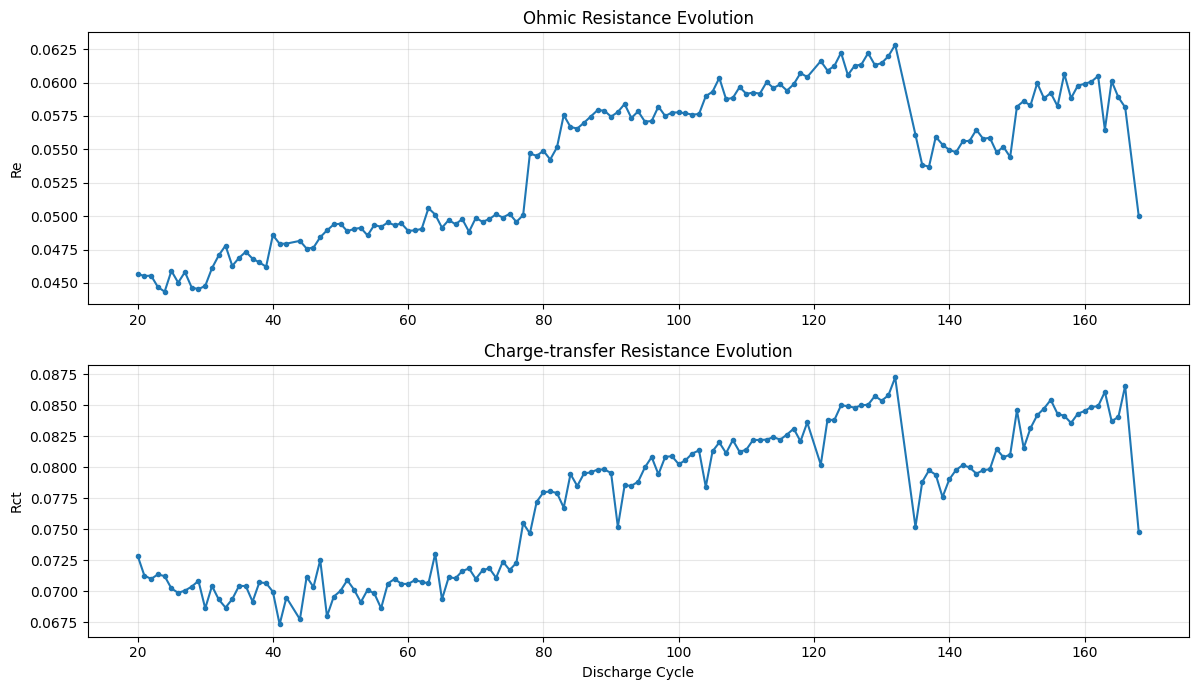

In [55]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(
    impedance_valid["record_index"],
    impedance_valid["Re_mean"],
    marker="o",
    markersize=3
)
axes[0].set_ylabel("Re")
axes[0].set_title("Ohmic Resistance Evolution")
axes[0].grid(alpha=0.3)

axes[1].plot(
    impedance_valid["record_index"],
    impedance_valid["Rct_mean"],
    marker="o",
    markersize=3
)
axes[1].set_xlabel("Discharge Cycle")
axes[1].set_ylabel("Rct")
axes[1].set_title("Charge-transfer Resistance Evolution")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

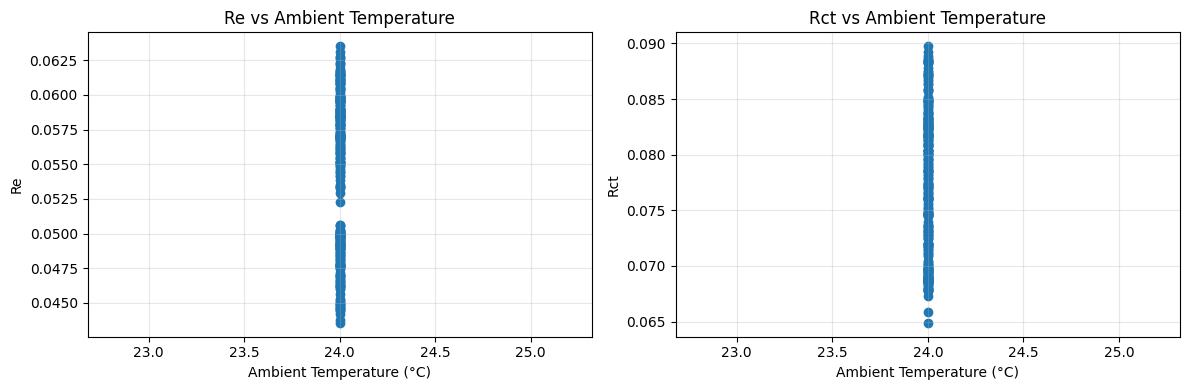

count    278.0
mean      24.0
std        0.0
min       24.0
25%       24.0
50%       24.0
75%       24.0
max       24.0
Name: ambient_temperature, dtype: float64


In [56]:
# Extract ambient temperature for each impedance record
impedance_ambient = []

for i, record in enumerate(impedance_records):
    impedance_ambient.append({
        "impedance_index": i + 1,
        "ambient_temperature": float(record.ambient_temperature)
    })

impedance_temp_df = pd.DataFrame(impedance_ambient)

# Merge with impedance measurements
impedance_temp_df = impedance_df.merge(
    impedance_temp_df,
    on="impedance_index"
)

# Plot resistance against ambient temperature
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(
    impedance_temp_df["ambient_temperature"],
    impedance_temp_df["Re"]
)
axes[0].set_xlabel("Ambient Temperature (°C)")
axes[0].set_ylabel("Re")
axes[0].set_title("Re vs Ambient Temperature")
axes[0].grid(alpha=0.3)

axes[1].scatter(
    impedance_temp_df["ambient_temperature"],
    impedance_temp_df["Rct"]
)
axes[1].set_xlabel("Ambient Temperature (°C)")
axes[1].set_ylabel("Rct")
axes[1].set_title("Rct vs Ambient Temperature")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(impedance_temp_df["ambient_temperature"].describe())

In [57]:
# Inspect the first impedance measurement
first_impedance = impedance_records[0].data

print("Available impedance fields:")
print(first_impedance._fieldnames)

print("\nSense current:")
print(first_impedance.Sense_current[:5])

print("\nBattery impedance:")
print(first_impedance.Battery_impedance[:5])

print("\nRe:", first_impedance.Re)
print("Rct:", first_impedance.Rct)

Available impedance fields:
['Sense_current', 'Battery_current', 'Current_ratio', 'Battery_impedance', 'Rectified_Impedance', 'Re', 'Rct']

Sense current:
[ -1.         +1.j         820.60949707-36.23455048j
 827.2421875 -48.23122787j 827.19348145-56.19571686j
 824.92950439-53.24147797j]

Battery impedance:
[-0.43892625-0.1072983j   0.13008841-0.19711481j  0.05877056+0.03330657j
  0.00581351-0.06054655j  0.12608107-0.09044391j]

Re: 0.04466870036616091
Rct: 0.06945627304536996


In [58]:
# Inspect dimensions of complex impedance measurements
for field in [
    "Sense_current",
    "Battery_current",
    "Current_ratio",
    "Battery_impedance",
    "Rectified_Impedance"
]:
    values = np.asarray(getattr(first_impedance, field))

    print(
        f"{field}: shape={values.shape}, "
        f"dtype={values.dtype}"
    )

Sense_current: shape=(48,), dtype=complex128
Battery_current: shape=(48,), dtype=complex128
Current_ratio: shape=(48,), dtype=complex128
Battery_impedance: shape=(48,), dtype=complex128
Rectified_Impedance: shape=(39,), dtype=complex128


In [59]:
# Inspect the first impedance measurement's complex values
Z = np.asarray(first_impedance.Battery_impedance)

print("Real component:", np.real(Z)[:10])
print("Imaginary component:", np.imag(Z)[:10])
print("Magnitude:", np.abs(Z)[:10])

Real component: [-0.43892625  0.13008841  0.05877056  0.00581351  0.12608107  0.22105519
  0.24487369  0.23511369  0.22370348  0.22135401]
Imaginary component: [-0.1072983  -0.19711481  0.03330657 -0.06054655 -0.09044391 -0.00412578
  0.09777461  0.16534778  0.19445632  0.19369436]
Magnitude: [0.45185083 0.23617206 0.06755225 0.06082501 0.15516615 0.22109369
 0.26367214 0.28743405 0.29640599 0.2941345 ]


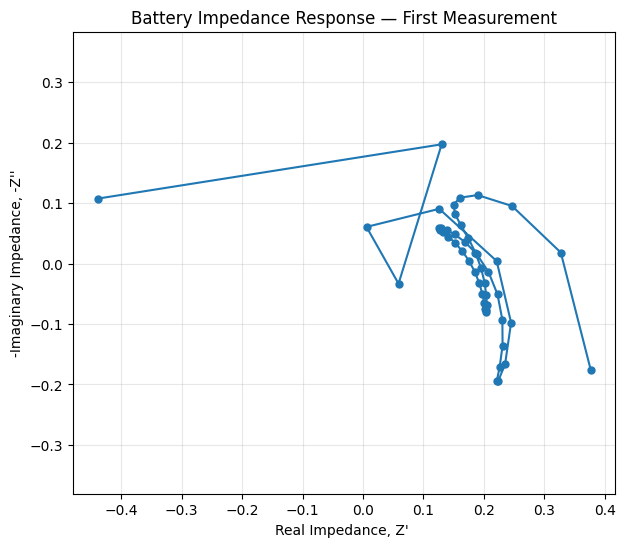

In [60]:
Z = np.asarray(first_impedance.Battery_impedance)

plt.figure(figsize=(7, 6))

plt.plot(
    np.real(Z),
    -np.imag(Z),
    marker="o",
    markersize=5
)

plt.xlabel("Real Impedance, Z' ")
plt.ylabel("-Imaginary Impedance, -Z''")
plt.title("Battery Impedance Response — First Measurement")
plt.grid(alpha=0.3)
plt.axis("equal")

plt.show()

In [61]:
# Inspect the sequence of impedance measurements
impedance_components = pd.DataFrame({
    "measurement_index": range(1, len(Z) + 1),
    "Z_real": np.real(Z),
    "Z_imaginary": np.imag(Z),
    "Z_magnitude": np.abs(Z)
})

impedance_components.head(15)

,measurement_index,Z_real,Z_imaginary,Z_magnitude
0,1,-0.438926,-0.107298,0.451851
1,2,0.130088,-0.197115,0.236172
2,3,0.058771,0.033307,0.067552
3,4,0.005814,-0.060547,0.060825
4,5,0.126081,-0.090444,0.155166
5,6,0.221055,-0.004126,0.221094
6,7,0.244874,0.097775,0.263672
7,8,0.235114,0.165348,0.287434
8,9,0.223703,0.194456,0.296406
9,10,0.221354,0.193694,0.294134


In [62]:
raw_Z = np.asarray(first_impedance.Battery_impedance)
rectified_Z = np.asarray(first_impedance.Rectified_Impedance)

print("Raw impedance:")
print("Length:", len(raw_Z))
print("First 10:", raw_Z[:10])

print("\nRectified impedance:")
print("Length:", len(rectified_Z))
print("First 10:", rectified_Z[:10])

Raw impedance:
Length: 48
First 10: [-0.43892625-0.1072983j   0.13008841-0.19711481j  0.05877056+0.03330657j
  0.00581351-0.06054655j  0.12608107-0.09044391j  0.22105519-0.00412578j
  0.24487369+0.09777461j  0.23511369+0.16534778j  0.22370348+0.19445632j
  0.22135401+0.19369436j]

Rectified impedance:
Length: 39
First 10: [0.07006938-4.79984691e-04j 0.06817886-1.19004093e-03j
 0.06793258-5.68268119e-05j 0.06691839-8.78726402e-04j
 0.06807105-1.97480202e-04j 0.06657097-5.84414924e-04j
 0.06841818-9.57364172e-04j 0.06772415-4.76753624e-04j
 0.06579332-6.44553997e-04j 0.06682467-8.02839440e-04j]


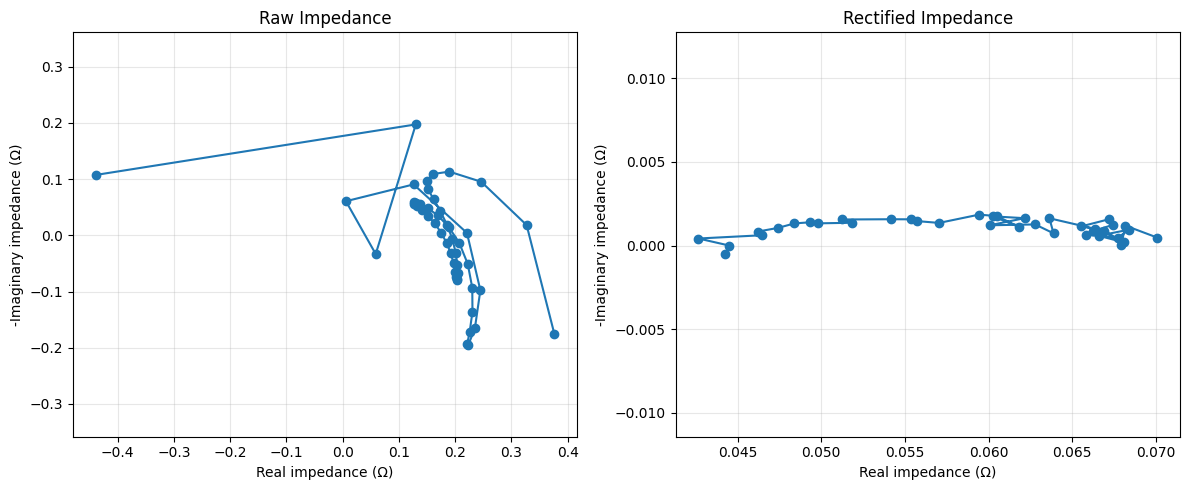

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(np.real(raw_Z), -np.imag(raw_Z), marker="o")
axes[0].set_title("Raw Impedance")
axes[0].set_xlabel("Real impedance (Ω)")
axes[0].set_ylabel("-Imaginary impedance (Ω)")
axes[0].grid(alpha=0.3)
axes[0].axis("equal")

axes[1].plot(
    np.real(rectified_Z),
    -np.imag(rectified_Z),
    marker="o"
)
axes[1].set_title("Rectified Impedance")
axes[1].set_xlabel("Real impedance (Ω)")
axes[1].set_ylabel("-Imaginary impedance (Ω)")
axes[1].grid(alpha=0.3)
axes[1].axis("equal")

plt.tight_layout()
plt.show()

In [64]:
rectified_features = []

for i, record in enumerate(impedance_records):
    Z_rect = np.asarray(record.data.Rectified_Impedance)

    rectified_features.append({
        "impedance_index": i + 1,
        "rectified_real_mean": np.mean(np.real(Z_rect)),
        "rectified_real_std": np.std(np.real(Z_rect)),
        "rectified_imag_mean": np.mean(np.imag(Z_rect)),
        "rectified_magnitude_mean": np.mean(np.abs(Z_rect))
    })

rectified_df = pd.DataFrame(rectified_features)

rectified_df.describe()

,impedance_index,rectified_real_mean,rectified_real_std,rectified_imag_mean,rectified_magnitude_mean
count,278.000000,278.000000,278.000000,278.000000,278.000000
mean,139.500000,0.067925,0.008389,-0.001077,0.067937
std,80.395895,0.005926,0.000849,0.000169,0.005927
min,1.000000,0.057830,0.006822,-0.001541,0.057842
25%,70.250000,0.061798,0.007689,-0.001203,0.061808
50%,139.500000,0.069241,0.008376,-0.001049,0.069252
75%,208.750000,0.072635,0.008910,-0.000946,0.072649
max,278.000000,0.078350,0.010821,-0.000689,0.078364


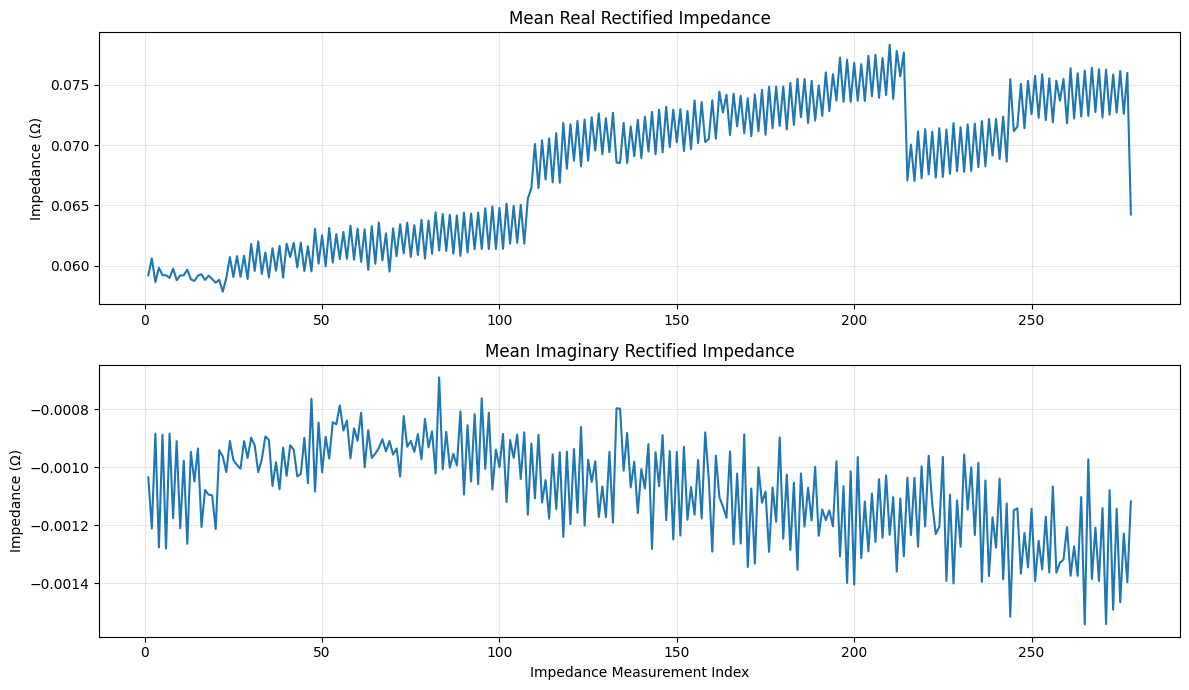

In [65]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(
    rectified_df["impedance_index"],
    rectified_df["rectified_real_mean"]
)
axes[0].set_title("Mean Real Rectified Impedance")
axes[0].set_ylabel("Impedance (Ω)")
axes[0].grid(alpha=0.3)

axes[1].plot(
    rectified_df["impedance_index"],
    rectified_df["rectified_imag_mean"]
)
axes[1].set_title("Mean Imaginary Rectified Impedance")
axes[1].set_xlabel("Impedance Measurement Index")
axes[1].set_ylabel("Impedance (Ω)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [66]:
# Merge rectified impedance features with the existing impedance dataset
impedance_comparison = impedance_df.merge(
    rectified_df[
        [
            "impedance_index",
            "rectified_real_mean",
            "rectified_real_std",
            "rectified_imag_mean"
        ]
    ],
    on="impedance_index"
)

# Calculate correlations
correlation_columns = [
    "Re",
    "Rct",
    "rectified_real_mean",
    "rectified_real_std",
    "rectified_imag_mean"
]

impedance_correlation = impedance_comparison[
    correlation_columns
].corr(method="pearson")

impedance_correlation

,Re,Rct,rectified_real_mean,rectified_real_std,rectified_imag_mean
Re,1.000000,0.880426,0.955416,0.156024,-0.512910
Rct,0.880426,1.000000,0.970004,0.561882,-0.785650
rectified_real_mean,0.955416,0.970004,1.000000,0.389777,-0.678399
rectified_real_std,0.156024,0.561882,0.389777,1.000000,-0.811959
rectified_imag_mean,-0.512910,-0.785650,-0.678399,-0.811959,1.000000


In [67]:
# Save impedance analysis results
impedance_comparison.to_csv(
    "B0005_impedance_analysis.csv",
    index=False
)

final_df.to_csv(
    "B0005_final_dataset.csv",
    index=False
)

print("Files saved successfully:")
print("1. B0005_impedance_analysis.csv")
print("2. B0005_final_dataset.csv")

Files saved successfully:
1. B0005_impedance_analysis.csv
2. B0005_final_dataset.csv


In [68]:
from scipy.stats import pearsonr, spearmanr

# Use only past-only impedance matches within 1 hour
model_data = final_df.dropna(
    subset=["Re", "Rct"]
).copy()

print("Valid observations:", len(model_data))

for feature in ["Re", "Rct"]:
    pearson_corr, pearson_p = pearsonr(
        model_data[feature],
        model_data["SoH_percent"]
    )

    spearman_corr, spearman_p = spearmanr(
        model_data[feature],
        model_data["SoH_percent"]
    )

    print(f"\n{feature}")
    print(f"Pearson:  {pearson_corr:.4f} (p={pearson_p:.4g})")
    print(f"Spearman: {spearman_corr:.4f} (p={spearman_p:.4g})")

Valid observations: 132

Re
Pearson:  -0.8833 (p=1.318e-44)
Spearman: -0.8111 (p=4.536e-32)

Rct
Pearson:  -0.9435 (p=3.133e-64)
Spearman: -0.9092 (p=2.641e-51)


In [69]:
# Full dataset: all 168 discharge cycles
full_model_data = final_df.copy()

# Impedance dataset: only 132 valid past-only matches
impedance_model_data = final_df.dropna(
    subset=["Re", "Rct"]
).copy()

print("Full dataset:", full_model_data.shape)
print("Impedance dataset:", impedance_model_data.shape)

print("\nMissing values in impedance dataset:")
print(
    impedance_model_data[
        ["Re", "Rct"]
    ].isna().sum()
)

Full dataset: (168, 16)
Impedance dataset: (132, 16)

Missing values in impedance dataset:
Re     0
Rct    0
dtype: int64


In [70]:
# Define target
target = "SoH_percent"

# Model A: electrical and thermal features
features_A = [
    "voltage_mean",
    "voltage_min",
    "voltage_max",
    "current_mean",
    "temperature_mean",
    "temperature_max",
    "temperature_rise"
]

# Model B: electrical, thermal and impedance features
features_B = features_A + [
    "Re",
    "Rct"
]

# Use the same 132 observations for both experiments
X_A = impedance_model_data[features_A]
X_B = impedance_model_data[features_B]

y = impedance_model_data[target]

print("Model A features:", X_A.shape)
print("Model B features:", X_B.shape)
print("Target:", y.shape)

Model A features: (132, 7)
Model B features: (132, 9)
Target: (132,)


In [71]:
from sklearn.model_selection import train_test_split

# Chronological split: first 80% for training, last 20% for testing
split_index = int(len(impedance_model_data) * 0.8)

X_A_train = X_A.iloc[:split_index]
X_A_test = X_A.iloc[split_index:]

X_B_train = X_B.iloc[:split_index]
X_B_test = X_B.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training observations:", len(y_train))
print("Testing observations:", len(y_test))

print("\nTraining cycle range:")
print(
    impedance_model_data["record_index"].iloc[0],
    "to",
    impedance_model_data["record_index"].iloc[split_index - 1]
)

print("\nTesting cycle range:")
print(
    impedance_model_data["record_index"].iloc[split_index],
    "to",
    impedance_model_data["record_index"].iloc[-1]
)

Training observations: 105
Testing observations: 27

Training cycle range:
20 to 138

Testing cycle range:
139 to 166


In [72]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train Model A: voltage and temperature
model_A = LinearRegression()
model_A.fit(X_A_train, y_train)

# Train Model B: voltage, temperature and impedance
model_B = LinearRegression()
model_B.fit(X_B_train, y_train)

# Generate predictions
pred_A = model_A.predict(X_A_test)
pred_B = model_B.predict(X_B_test)

# Evaluation function
def evaluate_model(y_true, predictions, model_name):
    mae = mean_absolute_error(y_true, predictions)
    rmse = np.sqrt(mean_squared_error(y_true, predictions))
    r2 = r2_score(y_true, predictions)

    print(f"\n{model_name}")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}")

# Evaluate both models
evaluate_model(y_test, pred_A, "Model A — Voltage and Temperature")
evaluate_model(y_test, pred_B, "Model B — With Impedance")


Model A — Voltage and Temperature
MAE:  0.5469
RMSE: 0.6118
R²:   0.6110

Model B — With Impedance
MAE:  0.7549
RMSE: 0.7827
R²:   0.3632


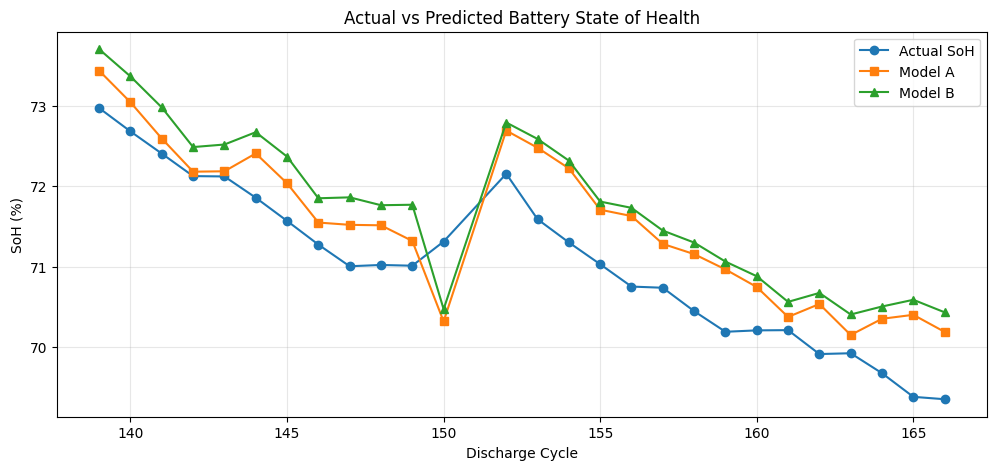

,Cycle,Actual_SoH,Model_A_Predicted,Model_B_Predicted
138,139,72.971349,73.436924,73.703943
139,140,72.681074,73.043672,73.365196
140,141,72.404972,72.592348,72.979380
141,142,72.124991,72.180054,72.486445
142,143,72.120851,72.185129,72.518179
143,144,71.856489,72.407383,72.671460
144,145,71.567651,72.035930,72.367781
145,146,71.272818,71.547143,71.849265
146,147,71.003398,71.518785,71.860711
147,148,71.019412,71.512826,71.762817


In [73]:
# Compare actual and predicted SoH
comparison_df = pd.DataFrame({
    "Cycle": impedance_model_data["record_index"].iloc[split_index:],
    "Actual_SoH": y_test.values,
    "Model_A_Predicted": pred_A,
    "Model_B_Predicted": pred_B
})

plt.figure(figsize=(12, 5))

plt.plot(
    comparison_df["Cycle"],
    comparison_df["Actual_SoH"],
    marker="o",
    label="Actual SoH"
)

plt.plot(
    comparison_df["Cycle"],
    comparison_df["Model_A_Predicted"],
    marker="s",
    label="Model A"
)

plt.plot(
    comparison_df["Cycle"],
    comparison_df["Model_B_Predicted"],
    marker="^",
    label="Model B"
)

plt.xlabel("Discharge Cycle")
plt.ylabel("SoH (%)")
plt.title("Actual vs Predicted Battery State of Health")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

comparison_df

In [74]:
# Extract coefficients from both models
coefficients_df = pd.DataFrame({
    "Feature": features_B,
    "Model_A_Coefficient": [
        model_A.coef_[features_A.index(f)] if f in features_A else np.nan
        for f in features_B
    ],
    "Model_B_Coefficient": model_B.coef_
})

coefficients_df

,Feature,Model_A_Coefficient,Model_B_Coefficient
0,voltage_mean,223.440699,198.622276
1,voltage_min,-20.335219,-20.056532
2,voltage_max,72.777537,80.746359
3,current_mean,3.845342,0.111974
4,temperature_mean,5.251815,5.723708
5,temperature_max,-6.017503,-6.412207
6,temperature_rise,0.656601,0.646308
7,Re,NaN,-38.320508
8,Rct,NaN,-16.287042


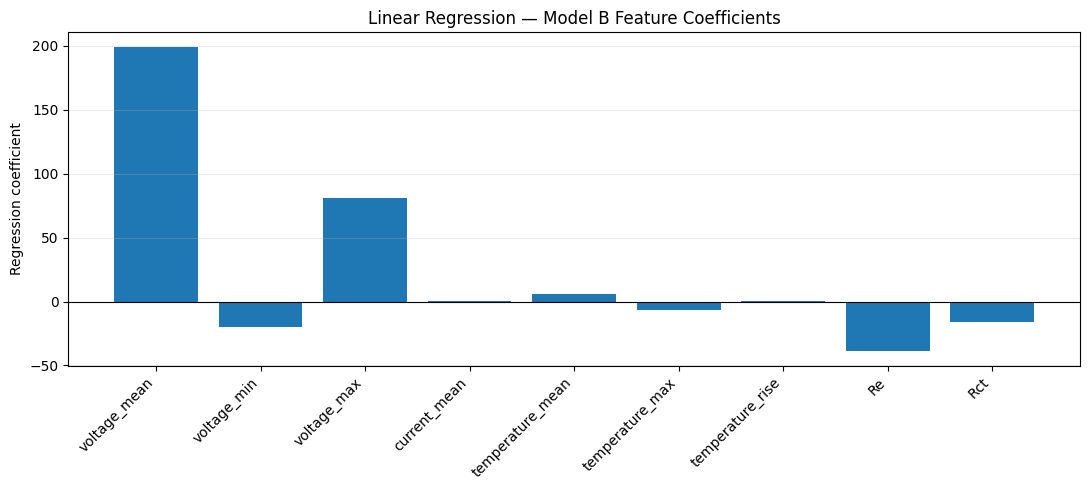

In [75]:
# Display coefficients visually
plt.figure(figsize=(11, 5))

plt.bar(
    coefficients_df["Feature"],
    coefficients_df["Model_B_Coefficient"]
)

plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Regression coefficient")
plt.title("Linear Regression — Model B Feature Coefficients")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [76]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

# Standardise predictors for numerical stability
scaler = StandardScaler()
X_B_scaled = scaler.fit_transform(X_B_train)

vif_df = pd.DataFrame({
    "Feature": features_B,
    "VIF": [
        variance_inflation_factor(X_B_scaled, i)
        for i in range(X_B_scaled.shape[1])
    ]
})

vif_df.sort_values("VIF", ascending=False)

,Feature,VIF
5,temperature_max,1242.899259
4,temperature_mean,600.731619
6,temperature_rise,316.013409
0,voltage_mean,264.143359
3,current_mean,130.833651
8,Rct,43.810075
7,Re,24.970179
2,voltage_max,3.151796
1,voltage_min,1.779186


In [77]:
reduced_features = [
    "voltage_mean",
    "voltage_min",
    "temperature_rise",
    "Re",
    "Rct"
]

X_reduced = impedance_model_data[reduced_features]
X_reduced_train = X_reduced.iloc[:split_index]

scaler_reduced = StandardScaler()
X_reduced_scaled = scaler_reduced.fit_transform(
    X_reduced_train
)

reduced_vif_df = pd.DataFrame({
    "Feature": reduced_features,
    "VIF": [
        variance_inflation_factor(X_reduced_scaled, i)
        for i in range(X_reduced_scaled.shape[1])
    ]
})

reduced_vif_df.sort_values("VIF", ascending=False)

,Feature,VIF
0,voltage_mean,38.703967
4,Rct,35.161654
2,temperature_rise,24.905325
3,Re,17.261815
1,voltage_min,1.269447


In [78]:
diagnostic_features = [
    "voltage_min",
    "temperature_rise",
    "Re",
    "Rct"
]

X_diagnostic = impedance_model_data[
    diagnostic_features
].iloc[:split_index]

X_diagnostic_scaled = StandardScaler().fit_transform(
    X_diagnostic
)

diagnostic_vif = pd.DataFrame({
    "Feature": diagnostic_features,
    "VIF": [
        variance_inflation_factor(
            X_diagnostic_scaled, i
        )
        for i in range(len(diagnostic_features))
    ]
})

diagnostic_vif.sort_values("VIF", ascending=False)

,Feature,VIF
3,Rct,26.648441
2,Re,16.978730
1,temperature_rise,9.517760
0,voltage_min,1.182387


In [79]:
# Compare two alternative feature combinations
feature_sets = {
    "Without Re": [
        "voltage_min",
        "temperature_rise",
        "Rct"
    ],
    "Without Rct": [
        "voltage_min",
        "temperature_rise",
        "Re"
    ]
}

for name, selected_features in feature_sets.items():

    X_temp = impedance_model_data[
        selected_features
    ].iloc[:split_index]

    X_scaled = StandardScaler().fit_transform(X_temp)

    print(f"\n{name}")

    for i, feature in enumerate(selected_features):
        vif = variance_inflation_factor(X_scaled, i)
        print(f"{feature}: {vif:.3f}")


Without Re
voltage_min: 1.180
temperature_rise: 9.508
Rct: 9.761

Without Rct
voltage_min: 1.162
temperature_rise: 6.171
Re: 6.219


In [80]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Ridge A: Voltage and temperature
ridge_A = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

# Ridge B: Voltage, temperature and impedance
ridge_B = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

# Train
ridge_A.fit(X_A_train, y_train)
ridge_B.fit(X_B_train, y_train)

# Predict
ridge_pred_A = ridge_A.predict(X_A_test)
ridge_pred_B = ridge_B.predict(X_B_test)

# Evaluate
evaluate_model(
    y_test,
    ridge_pred_A,
    "Ridge Regression — Voltage and Temperature"
)

evaluate_model(
    y_test,
    ridge_pred_B,
    "Ridge Regression — With Impedance"
)


Ridge Regression — Voltage and Temperature
MAE:  0.3620
RMSE: 0.4093
R²:   0.8259

Ridge Regression — With Impedance
MAE:  0.7342
RMSE: 0.7624
R²:   0.3959


In [81]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

# Tune Model A
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

param_grid = {
    "ridge__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

tscv = TimeSeriesSplit(n_splits=5)

grid_A = GridSearchCV(
    ridge_pipeline,
    param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error"
)

grid_A.fit(X_A_train, y_train)

print("Best alpha:", grid_A.best_params_["ridge__alpha"])
print("Best validation MAE:", -grid_A.best_score_)

Best alpha: 0.001
Best validation MAE: 1.0804707463773262


In [82]:
# Retrieve the best Ridge model
best_ridge_A = grid_A.best_estimator_

# Predict on the untouched test set
tuned_ridge_pred_A = best_ridge_A.predict(X_A_test)

# Evaluate
evaluate_model(
    y_test,
    tuned_ridge_pred_A,
    "Optimised Ridge — Voltage and Temperature"
)


Optimised Ridge — Voltage and Temperature
MAE:  0.5445
RMSE: 0.6099
R²:   0.6133


In [83]:
fold_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_A_train), start=1):
    X_fold_train = X_A_train.iloc[train_idx]
    X_fold_val = X_A_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    )

    model.fit(X_fold_train, y_fold_train)
    predictions = model.predict(X_fold_val)

    fold_mae = mean_absolute_error(y_fold_val, predictions)

    fold_results.append({
        "Fold": fold,
        "Training samples": len(train_idx),
        "Validation samples": len(val_idx),
        "Validation MAE": fold_mae
    })

pd.DataFrame(fold_results)

,Fold,Training samples,Validation samples,Validation MAE
0,1,20,17,2.711306
1,2,37,17,1.256391
2,3,54,17,0.600042
3,4,71,17,0.836431
4,5,88,17,0.906120


In [84]:
alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

ridge_cv_results = []

for alpha in alpha_values:
    fold_maes = []

    for train_idx, val_idx in tscv.split(X_A_train):
        X_fold_train = X_A_train.iloc[train_idx]
        X_fold_val = X_A_train.iloc[val_idx]

        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        model = make_pipeline(
            StandardScaler(),
            Ridge(alpha=alpha)
        )

        model.fit(X_fold_train, y_fold_train)
        predictions = model.predict(X_fold_val)

        fold_maes.append(
            mean_absolute_error(y_fold_val, predictions)
        )

    ridge_cv_results.append({
        "Alpha": alpha,
        "Fold 1 MAE": fold_maes[0],
        "Fold 2 MAE": fold_maes[1],
        "Fold 3 MAE": fold_maes[2],
        "Fold 4 MAE": fold_maes[3],
        "Fold 5 MAE": fold_maes[4],
        "Mean CV MAE": np.mean(fold_maes)
    })

ridge_cv_comparison = pd.DataFrame(ridge_cv_results)
ridge_cv_comparison

,Alpha,Fold 1 MAE,Fold 2 MAE,Fold 3 MAE,Fold 4 MAE,Fold 5 MAE,Mean CV MAE
0,0.001,1.221249,1.119004,0.917747,1.144031,1.000322,1.080471
1,0.010,1.359988,1.160373,0.912187,1.120349,0.984389,1.107457
2,0.100,1.989890,1.253746,0.848040,1.005635,0.934706,1.206403
3,1.000,2.711306,1.256391,0.600042,0.836431,0.906120,1.262058
4,10.000,3.444607,1.922765,0.899224,0.874940,1.086734,1.645654
5,100.000,3.910815,5.016496,3.408566,3.069531,3.502906,3.781663


In [85]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rf_A = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

rf_A.fit(X_A_train, y_train)

rf_predictions_A = rf_A.predict(X_A_test)

evaluate_model(
    y_test,
    rf_predictions_A,
    "Random Forest — Voltage and Temperature"
)


Random Forest — Voltage and Temperature
MAE:  2.4350
RMSE: 2.6172
R²:   -6.1192


In [86]:
rf_comparison = pd.DataFrame({
    "Actual SoH": y_test.values,
    "Predicted SoH": rf_predictions_A
})

rf_comparison["Error"] = (
    rf_comparison["Predicted SoH"] -
    rf_comparison["Actual SoH"]
)

print(rf_comparison.head(10))

print("\nActual SoH range:")
print(y_train.min(), "to", y_train.max())

print("\nPredicted SoH range:")
print(rf_predictions_A.min(), "to", rf_predictions_A.max())

   Actual SoH  Predicted SoH     Error
0   72.971349      73.523209  0.551859
1   72.681074      73.564295  0.883221
2   72.404972      73.585360  1.180389
3   72.124991      73.435490  1.310499
4   72.120851      73.463591  1.342740
5   71.856489      73.538108  1.681619
6   71.567651      73.443148  1.875497
7   71.272818      73.524042  2.251224
8   71.003398      73.509469  2.506070
9   71.019412      73.436234  2.416823

Actual SoH range:
72.95077959801873 to 99.5114370594272

Predicted SoH range:
73.39792176256172 to 73.58536031840389


In [87]:
rf_B = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

rf_B.fit(X_B_train, y_train)

rf_predictions_B = rf_B.predict(X_B_test)

evaluate_model(
    y_test,
    rf_predictions_B,
    "Random Forest — Voltage, Temperature and Impedance"
)


Random Forest — Voltage, Temperature and Impedance
MAE:  2.5105
RMSE: 2.6886
R²:   -6.5130


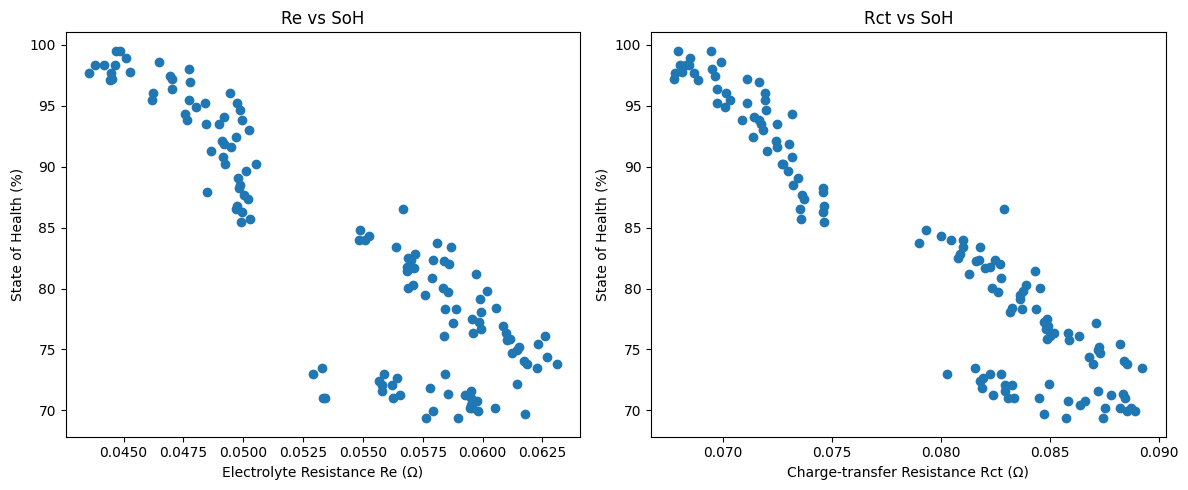

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    impedance_model_data["Re"],
    impedance_model_data["SoH_percent"]
)
axes[0].set_xlabel("Electrolyte Resistance Re (Ω)")
axes[0].set_ylabel("State of Health (%)")
axes[0].set_title("Re vs SoH")

axes[1].scatter(
    impedance_model_data["Rct"],
    impedance_model_data["SoH_percent"]
)
axes[1].set_xlabel("Charge-transfer Resistance Rct (Ω)")
axes[1].set_ylabel("State of Health (%)")
axes[1].set_title("Rct vs SoH")

plt.tight_layout()
plt.show()

In [89]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_physics = impedance_model_data[["Re", "Rct"]]
y_physics = impedance_model_data["SoH_percent"]

X_physics_train = X_physics.iloc[:split_index]
X_physics_test = X_physics.iloc[split_index:]

y_physics_train = y_physics.iloc[:split_index]
y_physics_test = y_physics.iloc[split_index:]

physics_model = LinearRegression()

physics_model.fit(X_physics_train, y_physics_train)

physics_predictions = physics_model.predict(X_physics_test)

evaluate_model(
    y_physics_test,
    physics_predictions,
    "Resistance-Based Model — Re and Rct"
)


Resistance-Based Model — Re and Rct
MAE:  5.8278
RMSE: 6.3595
R²:   -41.0343


In [90]:
physics_comparison = pd.DataFrame({
    "Actual SoH": y_physics_test.values,
    "Predicted SoH": physics_predictions
})

physics_comparison["Error"] = (
    physics_comparison["Predicted SoH"] -
    physics_comparison["Actual SoH"]
)

print(physics_comparison.head(10))

print("\nTraining feature ranges:")
print(X_physics_train.describe().loc[["min", "max"]])

print("\nTesting feature ranges:")
print(X_physics_test.describe().loc[["min", "max"]])

print("\nPredicted SoH range:")
print(
    physics_predictions.min(),
    "to",
    physics_predictions.max()
)

   Actual SoH  Predicted SoH     Error
0   72.971349      82.956330  9.984981
1   72.681074      80.980266  8.299192
2   72.404972      81.156043  8.751071
3   72.124991      79.335201  7.210211
4   72.120851      79.733145  7.612294
5   71.856489      81.010698  9.154209
6   71.567651      79.737137  8.169487
7   71.272818      80.433250  9.160432
8   71.003398      77.862186  6.858787
9   71.019412      79.595008  8.575596

Training feature ranges:
           Re       Rct
min  0.043559  0.067794
max  0.063104  0.089231

Testing feature ranges:
           Re       Rct
min  0.053344  0.080298
max  0.061759  0.088905

Predicted SoH range:
72.53664172229962 to 82.95633026617276


In [91]:
print("TRAINING DATA")
print(
    impedance_model_data.iloc[:split_index][
        ["Re", "Rct", "SoH_percent"]
    ].corr()
)

print("\nTEST DATA")
print(
    impedance_model_data.iloc[split_index:][
        ["Re", "Rct", "SoH_percent"]
    ].corr()
)

print("\nMEAN VALUES")

print(
    impedance_model_data.iloc[:split_index][
        ["Re", "Rct", "SoH_percent"]
    ].mean()
)

print(
    impedance_model_data.iloc[split_index:][
        ["Re", "Rct", "SoH_percent"]
    ].mean()
)

TRAINING DATA
                   Re       Rct  SoH_percent
Re           1.000000  0.970020    -0.933611
Rct          0.970020  1.000000    -0.962685
SoH_percent -0.933611 -0.962685     1.000000

TEST DATA
                   Re       Rct  SoH_percent
Re           1.000000  0.544832    -0.355768
Rct          0.544832  1.000000    -0.685447
SoH_percent -0.355768 -0.685447     1.000000

MEAN VALUES
Re              0.053397
Rct             0.077667
SoH_percent    86.114529
dtype: float64
Re              0.058096
Rct             0.085324
SoH_percent    71.043679
dtype: float64


In [92]:
X_rct = impedance_model_data[["Rct"]]

X_rct_train = X_rct.iloc[:split_index]
X_rct_test = X_rct.iloc[split_index:]

rct_model = LinearRegression()

rct_model.fit(X_rct_train, y_physics_train)

rct_predictions = rct_model.predict(X_rct_test)

evaluate_model(
    y_physics_test,
    rct_predictions,
    "Resistance-Based Model — Rct Only"
)


Resistance-Based Model — Rct Only
MAE:  5.8373
RMSE: 6.3662
R²:   -41.1230


In [93]:
print("Rct model coefficient:", rct_model.coef_[0])
print("Rct model intercept:", rct_model.intercept_)

print("\nTraining Rct range:")
print(X_rct_train["Rct"].min(), X_rct_train["Rct"].max())

print("\nTest Rct range:")
print(X_rct_test["Rct"].min(), X_rct_test["Rct"].max())

Rct model coefficient: -1205.930205052659
Rct model intercept: 179.77608352309048

Training Rct range:
0.06779434699116274 0.08923087570947913

Test Rct range:
0.08029809490533976 0.08890519876854222


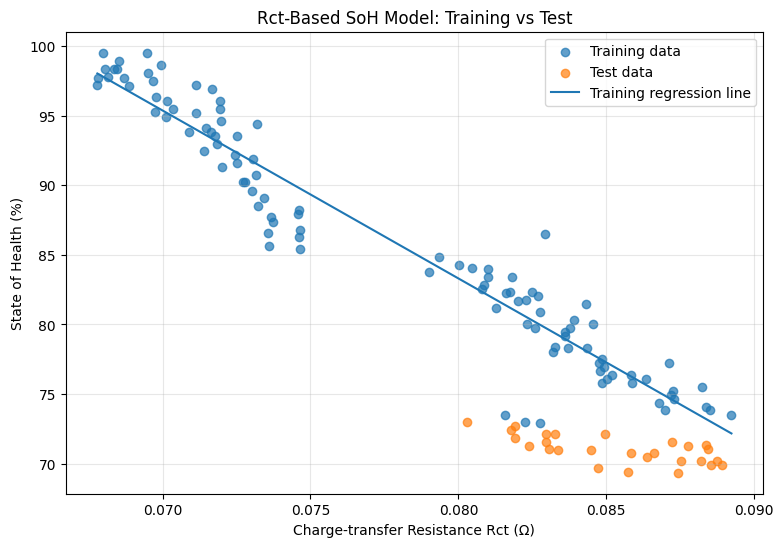

In [94]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_rct_train["Rct"],
    y_physics_train,
    label="Training data",
    alpha=0.7
)

plt.scatter(
    X_rct_test["Rct"],
    y_physics_test,
    label="Test data",
    alpha=0.7
)

rct_range = np.linspace(
    X_rct_train["Rct"].min(),
    X_rct_train["Rct"].max(),
    100
)

plt.plot(
    rct_range,
    rct_model.predict(pd.DataFrame({"Rct": rct_range})),
    label="Training regression line"
)

plt.xlabel("Charge-transfer Resistance Rct (Ω)")
plt.ylabel("State of Health (%)")
plt.title("Rct-Based SoH Model: Training vs Test")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [95]:
features_C = [
    "voltage_min",
    "temperature_rise",
    "Re",
    "Rct"
]

X_C = impedance_model_data[features_C]

X_C_train = X_C.iloc[:split_index]
X_C_test = X_C.iloc[split_index:]

ridge_C = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_C.fit(X_C_train, y_train)

ridge_predictions_C = ridge_C.predict(X_C_test)

evaluate_model(
    y_test,
    ridge_predictions_C,
    "Ridge — Reduced Physical and Electrical Features"
)


Ridge — Reduced Physical and Electrical Features
MAE:  2.1074
RMSE: 2.2522
R²:   -4.2718


In [96]:
ridge_C_comparison = pd.DataFrame({
    "Actual SoH": y_test.values,
    "Predicted SoH": ridge_predictions_C
})

ridge_C_comparison["Error"] = (
    ridge_C_comparison["Predicted SoH"] -
    ridge_C_comparison["Actual SoH"]
)

print(ridge_C_comparison.head(10))

print("\nActual SoH range:")
print(y_test.min(), "to", y_test.max())

print("\nPredicted SoH range:")
print(
    ridge_predictions_C.min(),
    "to",
    ridge_predictions_C.max()
)

   Actual SoH  Predicted SoH     Error
0   72.971349      76.828313  3.856964
1   72.681074      75.974497  3.293423
2   72.404972      75.445407  3.040435
3   72.124991      74.050678  1.925688
4   72.120851      74.191576  2.070725
5   71.856489      75.264494  3.408005
6   71.567651      74.625688  3.058038
7   71.272818      73.974084  2.701266
8   71.003398      72.838001  1.834603
9   71.019412      73.330724  2.311312

Actual SoH range:
69.34884167276275 to 72.97134934112401

Predicted SoH range:
70.81031978095153 to 76.828313047807


In [97]:
persistence_predictions = np.full(
    len(y_test),
    y_train.iloc[-1]
)

evaluate_model(
    y_test,
    persistence_predictions,
    "Persistence Baseline — Last Training SoH"
)


Persistence Baseline — Last Training SoH
MAE:  1.9246
RMSE: 2.1599
R²:   -3.8487


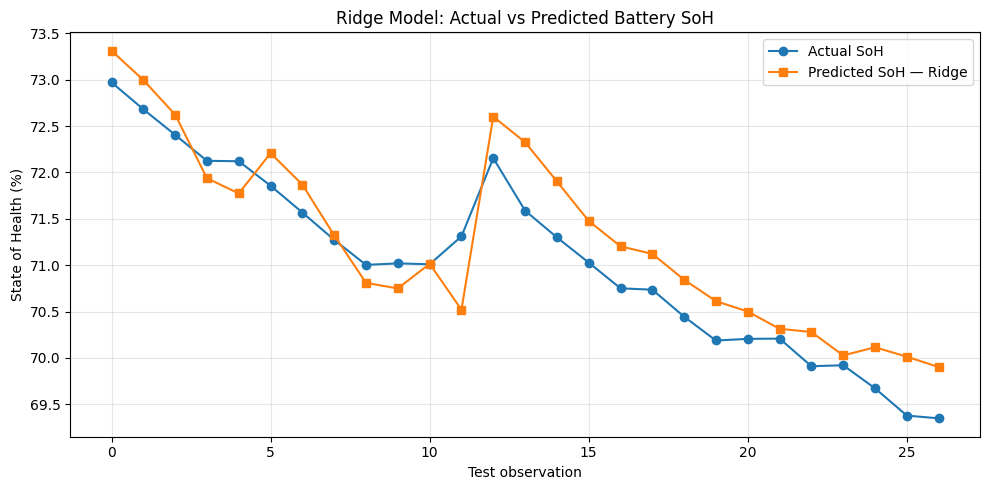

In [98]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(y_test)),
    y_test.values,
    marker="o",
    label="Actual SoH"
)

plt.plot(
    range(len(y_test)),
    ridge_A.predict(X_A_test),
    marker="s",
    label="Predicted SoH — Ridge"
)

plt.xlabel("Test observation")
plt.ylabel("State of Health (%)")
plt.title("Ridge Model: Actual vs Predicted Battery SoH")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [99]:
model_results = pd.DataFrame([
    {
        "Model": "Ridge — Voltage & Temperature",
        "MAE": 0.3620,
        "RMSE": 0.4093,
        "R2": 0.8259
    },
    {
        "Model": "Ridge — Tuned",
        "MAE": 0.5445,
        "RMSE": 0.6099,
        "R2": 0.6133
    },
    {
        "Model": "Ridge — Voltage, Temperature & Impedance",
        "MAE": 0.7342,
        "RMSE": 0.7624,
        "R2": 0.3959
    },
    {
        "Model": "Random Forest — Voltage & Temperature",
        "MAE": 2.4350,
        "RMSE": 2.6172,
        "R2": -6.1192
    },
    {
        "Model": "Random Forest — With Impedance",
        "MAE": 2.5105,
        "RMSE": 2.6886,
        "R2": -6.5130
    },
    {
        "Model": "Resistance — Re & Rct",
        "MAE": 5.8278,
        "RMSE": 6.3595,
        "R2": -41.0343
    },
    {
        "Model": "Persistence Baseline",
        "MAE": 1.9246,
        "RMSE": 2.1599,
        "R2": -3.8487
    }
])

model_results.sort_values("MAE")

,Model,MAE,RMSE,R2
0,Ridge — Voltage & Temperature,0.3620,0.4093,0.8259
1,Ridge — Tuned,0.5445,0.6099,0.6133
2,"Ridge — Voltage, Temperature & Impedance",0.7342,0.7624,0.3959
6,Persistence Baseline,1.9246,2.1599,-3.8487
3,Random Forest — Voltage & Temperature,2.4350,2.6172,-6.1192
4,Random Forest — With Impedance,2.5105,2.6886,-6.5130
5,Resistance — Re & Rct,5.8278,6.3595,-41.0343


In [100]:
model_results.to_csv(
    "B0005_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


In [101]:
import os
import glob

mat_files = glob.glob("*.mat")

print("Available battery files:")

for file in sorted(mat_files):
    print(f"{file} — {os.path.getsize(file) / 1024:.1f} KB")

Available battery files:
B0005.mat — 15582.9 KB


In [102]:
from google.colab import files

uploaded = files.upload()

Saving B0006.mat to B0006.mat
Saving B0007.mat to B0007.mat
Saving B0018.mat to B0018.mat


In [103]:
import glob
import os

mat_files = sorted(glob.glob("*.mat"))

print("Available battery files:")
for file in mat_files:
    print(f"{file} — {os.path.getsize(file) / 1024:.1f} KB")

Available battery files:
B0005.mat — 15582.9 KB
B0006.mat — 15652.5 KB
B0007.mat — 15673.3 KB
B0018.mat — 8302.9 KB


In [104]:
from scipy.io import loadmat
import numpy as np

for battery_id in ["B0006", "B0007", "B0018"]:
    mat = loadmat(
        f"{battery_id}.mat",
        squeeze_me=True,
        struct_as_record=False
    )

    battery = mat[battery_id]
    cycles = np.atleast_1d(battery.cycle)

    discharge_count = sum(
        1 for cycle in cycles
        if cycle.type == "discharge"
    )

    impedance_count = sum(
        1 for cycle in cycles
        if cycle.type == "impedance"
    )

    print(f"\n{battery_id}")
    print("Total records:", len(cycles))
    print("Discharge records:", discharge_count)
    print("Impedance records:", impedance_count)


B0006
Total records: 616
Discharge records: 168
Impedance records: 278

B0007
Total records: 616
Discharge records: 168
Impedance records: 278

B0018
Total records: 319
Discharge records: 132
Impedance records: 53


In [105]:
mat = loadmat(
    "B0018.mat",
    squeeze_me=True,
    struct_as_record=False
)

battery = mat["B0018"]
cycles = np.atleast_1d(battery.cycle)

discharge = next(c for c in cycles if c.type == "discharge")
impedance = next(c for c in cycles if c.type == "impedance")

print("Discharge fields:")
print(discharge.data._fieldnames)

print("\nImpedance fields:")
print(impedance.data._fieldnames)

Discharge fields:
['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity']

Impedance fields:
['Sense_current', 'Battery_current', 'Current_ratio', 'Battery_impedance', 'Rectified_Impedance', 'Re', 'Rct']


In [106]:
import numpy as np
import pandas as pd
from scipy.io import loadmat


def extract_discharge_features(battery_id):

    # 1. Load MATLAB file
    mat = loadmat(
        f"{battery_id}.mat",
        squeeze_me=True,
        struct_as_record=False
    )

    battery = mat[battery_id]
    cycles = np.atleast_1d(battery.cycle)

    rows = []

    # 2. Extract discharge cycles
    for record_index, cycle in enumerate(cycles):

        if cycle.type != "discharge":
            continue

        data = cycle.data

        voltage = np.asarray(data.Voltage_measured).ravel()
        current = np.asarray(data.Current_measured).ravel()
        temperature = np.asarray(data.Temperature_measured).ravel()
        time = np.asarray(data.Time).ravel()

        capacity = float(data.Capacity)

        # 3. Convert MATLAB date into pandas Timestamp
        date_components = np.asarray(cycle.time, dtype=float).ravel()

        seconds = date_components[5]
        whole_seconds = int(np.floor(seconds))
        fractional_seconds = seconds - whole_seconds

        timestamp = pd.Timestamp(
            year=int(date_components[0]),
            month=int(date_components[1]),
            day=int(date_components[2]),
            hour=int(date_components[3]),
            minute=int(date_components[4]),
            second=whole_seconds
        ) + pd.to_timedelta(fractional_seconds, unit="s")

        # 4. Extract cycle-level features
        rows.append({

            "battery_id": battery_id,
            "record_index": record_index,
            "timestamp": timestamp,

            "capacity_Ah": capacity,

            "voltage_mean": np.mean(voltage),
            "voltage_min": np.min(voltage),
            "voltage_max": np.max(voltage),

            "current_mean": np.mean(current),

            "temperature_mean": np.mean(temperature),
            "temperature_min": np.min(temperature),
            "temperature_max": np.max(temperature),

            "temperature_rise": np.max(temperature) - np.min(temperature),

            "discharge_duration_s": time[-1] - time[0]
        })

    # 5. Create DataFrame
    df = pd.DataFrame(rows)

    # 6. Calculate SoH using the battery's initial measured capacity
    initial_capacity = df["capacity_Ah"].iloc[0]

    df["SoH_percent"] = (
        df["capacity_Ah"] / initial_capacity
    ) * 100

    return df

In [107]:
test_df = extract_discharge_features("B0005")

print("Dataset shape:", test_df.shape)
display(test_df.head())

print("\nInitial capacity:", test_df["capacity_Ah"].iloc[0])
print("Initial SoH:", test_df["SoH_percent"].iloc[0])
print("Final SoH:", test_df["SoH_percent"].iloc[-1])

Dataset shape: (168, 14)


,battery_id,record_index,timestamp,capacity_Ah,voltage_mean,voltage_min,voltage_max,current_mean,temperature_mean,temperature_min,temperature_max,temperature_rise,discharge_duration_s,SoH_percent
0,B0005,1,2008-04-02 15:25:41.593,1.856487,3.529829,2.612467,4.191492,-1.818702,32.572328,24.325993,38.982181,14.656188,3690.234,100.000000
1,B0005,3,2008-04-02 19:43:48.406,1.846327,3.537320,2.587209,4.189773,-1.817560,32.725235,24.685948,39.033398,14.347450,3672.344,99.452721
2,B0005,5,2008-04-03 00:01:06.687,1.835349,3.543737,2.651917,4.188187,-1.816487,32.642862,24.734266,38.818797,14.084531,3651.641,98.861386
3,B0005,7,2008-04-03 04:16:37.375,1.835263,3.543666,2.592948,4.188461,-1.825589,32.514876,24.652244,38.762305,14.110061,3631.563,98.856718
4,B0005,9,2008-04-03 08:33:25.703,1.834646,3.542343,2.547420,4.188299,-1.826114,32.382349,24.518700,38.665393,14.146692,3629.172,98.823482



Initial capacity: 1.8564874208181574
Initial SoH: 100.0
Final SoH: 71.37561578838873


In [108]:
battery_ids = ["B0005", "B0006", "B0007", "B0018"]

battery_datasets = {}

for battery_id in battery_ids:

    df = extract_discharge_features(battery_id)

    battery_datasets[battery_id] = df

    print(f"\n{battery_id}")
    print("Number of cycles:", len(df))
    print("Initial capacity (Ah):", round(df["capacity_Ah"].iloc[0], 4))
    print("Final capacity (Ah):", round(df["capacity_Ah"].iloc[-1], 4))
    print("Final SoH (%):", round(df["SoH_percent"].iloc[-1], 2))


B0005
Number of cycles: 168
Initial capacity (Ah): 1.8565
Final capacity (Ah): 1.3251
Final SoH (%): 71.38

B0006
Number of cycles: 168
Initial capacity (Ah): 2.0353
Final capacity (Ah): 1.1857
Final SoH (%): 58.25

B0007
Number of cycles: 168
Initial capacity (Ah): 1.8911
Final capacity (Ah): 1.4325
Final SoH (%): 75.75

B0018
Number of cycles: 132
Initial capacity (Ah): 1.855
Final capacity (Ah): 1.3411
Final SoH (%): 72.29


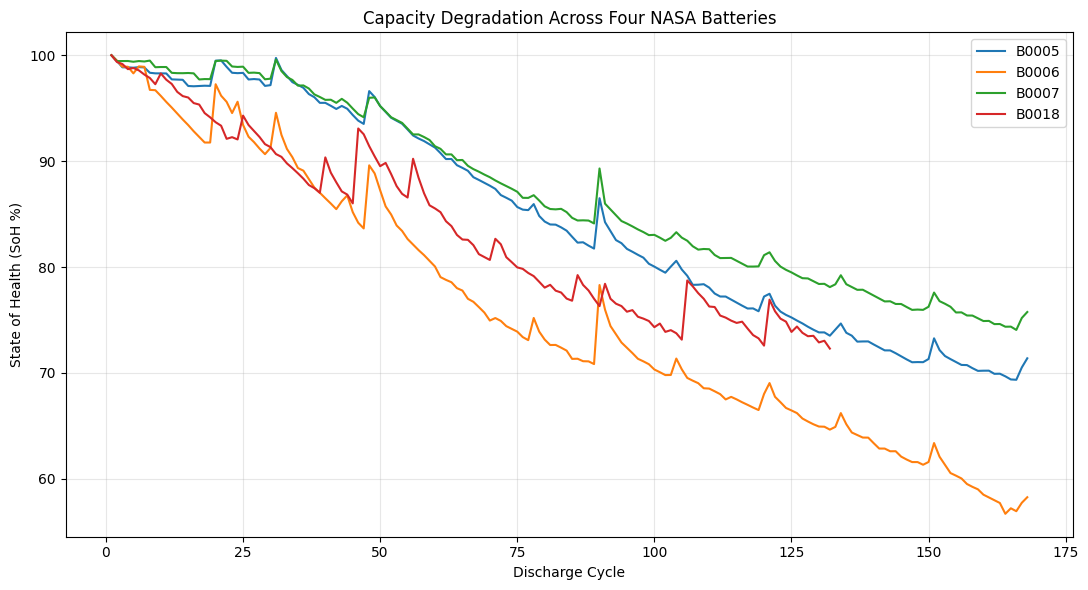

In [109]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

for battery_id, df in battery_datasets.items():

    plt.plot(
        range(1, len(df) + 1),
        df["SoH_percent"],
        label=battery_id
    )

plt.xlabel("Discharge Cycle")
plt.ylabel("State of Health (SoH %)")
plt.title("Capacity Degradation Across Four NASA Batteries")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [110]:
def extract_impedance_features(battery_id):

    mat = loadmat(
        f"{battery_id}.mat",
        squeeze_me=True,
        struct_as_record=False
    )

    battery = mat[battery_id]
    cycles = np.atleast_1d(battery.cycle)

    rows = []

    for record_index, cycle in enumerate(cycles):

        if cycle.type != "impedance":
            continue

        data = cycle.data

        date_components = np.asarray(
            cycle.time, dtype=float
        ).ravel()

        seconds = date_components[5]
        whole_seconds = int(np.floor(seconds))
        fractional_seconds = seconds - whole_seconds

        timestamp = pd.Timestamp(
            year=int(date_components[0]),
            month=int(date_components[1]),
            day=int(date_components[2]),
            hour=int(date_components[3]),
            minute=int(date_components[4]),
            second=whole_seconds
        ) + pd.to_timedelta(fractional_seconds, unit="s")

        rows.append({

            "battery_id": battery_id,
            "impedance_record_index": record_index,
            "impedance_timestamp": timestamp,

            "Re": float(data.Re),
            "Rct": float(data.Rct)
        })

    return pd.DataFrame(rows)

In [111]:
impedance_test = extract_impedance_features("B0005")

print("Dataset shape:", impedance_test.shape)
display(impedance_test.head())

print("\nRe statistics:")
print(impedance_test["Re"].describe())

print("\nRct statistics:")
print(impedance_test["Rct"].describe())

Dataset shape: (278, 5)


,battery_id,impedance_record_index,impedance_timestamp,Re,Rct
0,B0005,40,2008-04-18 20:55:29.859,0.044669,0.069456
1,B0005,42,2008-04-18 22:39:16.312,0.046687,0.076275
2,B0005,44,2008-04-19 02:14:27.015,0.044843,0.067972
3,B0005,46,2008-04-19 03:57:24.187,0.046195,0.074534
4,B0005,48,2008-04-19 07:32:33.656,0.045101,0.068528



Re statistics:
count    278.000000
mean       0.054245
std        0.005490
min        0.043559
25%        0.049161
50%        0.055850
75%        0.058815
max        0.063516
Name: Re, dtype: float64

Rct statistics:
count    278.000000
mean       0.077340
std        0.006367
min        0.064883
25%        0.071511
50%        0.077487
75%        0.082563
max        0.089757
Name: Rct, dtype: float64


In [112]:
def match_impedance_to_discharge(
    discharge_df,
    impedance_df,
    tolerance="1h"
):

    # Sort both datasets by timestamp
    discharge_sorted = discharge_df.sort_values(
        "timestamp"
    ).copy()

    impedance_sorted = impedance_df.sort_values(
        "impedance_timestamp"
    ).copy()

    # Match each discharge with its latest preceding
    # impedance measurement within the specified tolerance
    matched_df = pd.merge_asof(
        discharge_sorted,
        impedance_sorted[
            [
                "impedance_timestamp",
                "impedance_record_index",
                "Re",
                "Rct"
            ]
        ],
        left_on="timestamp",
        right_on="impedance_timestamp",
        direction="backward",
        tolerance=pd.Timedelta(tolerance)
    )

    # Calculate the age of the impedance measurement
    matched_df["impedance_age_hours"] = (
        matched_df["timestamp"]
        - matched_df["impedance_timestamp"]
    ).dt.total_seconds() / 3600

    return matched_df

In [113]:
matched_test = match_impedance_to_discharge(
    battery_datasets["B0005"],
    impedance_test
)

print("Total discharge cycles:", len(matched_test))

print(
    "Cycles with impedance:",
    matched_test["Re"].notna().sum()
)

print(
    "Cycles without impedance:",
    matched_test["Re"].isna().sum()
)

print("\nImpedance age statistics (hours):")
print(matched_test["impedance_age_hours"].describe())

display(matched_test.head(10))

Total discharge cycles: 168
Cycles with impedance: 132
Cycles without impedance: 36

Impedance age statistics (hours):
count    132.000000
mean       0.511892
std        0.088344
min        0.244996
25%        0.530739
50%        0.532493
75%        0.534081
max        0.945768
Name: impedance_age_hours, dtype: float64


,battery_id,record_index,timestamp,capacity_Ah,voltage_mean,voltage_min,voltage_max,current_mean,temperature_mean,temperature_min,temperature_max,temperature_rise,discharge_duration_s,SoH_percent,impedance_timestamp,impedance_record_index,Re,Rct,impedance_age_hours
0,B0005,1,2008-04-02 15:25:41.593,1.856487,3.529829,2.612467,4.191492,-1.818702,32.572328,24.325993,38.982181,14.656188,3690.234,100.000000,NaT,NaN,NaN,NaN,NaN
1,B0005,3,2008-04-02 19:43:48.406,1.846327,3.537320,2.587209,4.189773,-1.817560,32.725235,24.685948,39.033398,14.347450,3672.344,99.452721,NaT,NaN,NaN,NaN,NaN
2,B0005,5,2008-04-03 00:01:06.687,1.835349,3.543737,2.651917,4.188187,-1.816487,32.642862,24.734266,38.818797,14.084531,3651.641,98.861386,NaT,NaN,NaN,NaN,NaN
3,B0005,7,2008-04-03 04:16:37.375,1.835263,3.543666,2.592948,4.188461,-1.825589,32.514876,24.652244,38.762305,14.110061,3631.563,98.856718,NaT,NaN,NaN,NaN,NaN
4,B0005,9,2008-04-03 08:33:25.703,1.834646,3.542343,2.547420,4.188299,-1.826114,32.382349,24.518700,38.665393,14.146692,3629.172,98.823482,NaT,NaN,NaN,NaN,NaN
5,B0005,11,2008-04-03 12:55:10.687,1.835662,3.541335,2.520948,4.188816,-1.816811,32.434182,24.514427,38.751695,14.237268,3652.281,98.878217,NaT,NaN,NaN,NaN,NaN
6,B0005,13,2008-04-03 17:17:16.015,1.835146,3.541025,2.487927,4.188392,-1.816791,32.480416,24.575581,38.820701,14.245120,3650.828,98.850449,NaT,NaN,NaN,NaN,NaN
7,B0005,15,2008-04-03 21:28:14.718,1.825757,3.554133,2.665205,4.188928,-1.844341,32.410462,24.711324,38.517130,13.805806,3572.453,98.344690,NaT,NaN,NaN,NaN,NaN
8,B0005,17,2008-04-04 01:38:15.218,1.824774,3.552936,2.603858,4.189029,-1.853973,32.346141,24.628487,38.526268,13.897781,3550.594,98.291743,NaT,NaN,NaN,NaN,NaN
9,B0005,19,2008-04-04 05:48:08.609,1.824613,3.551206,2.552854,4.189223,-1.853590,32.276798,24.561560,38.526981,13.965421,3551.250,98.283094,NaT,NaN,NaN,NaN,NaN


In [114]:
impedance_datasets = {}
matched_datasets = {}

for battery_id in battery_ids:

    # Extract impedance measurements
    impedance_df = extract_impedance_features(battery_id)

    # Match them with discharge measurements
    matched_df = match_impedance_to_discharge(
        battery_datasets[battery_id],
        impedance_df,
        tolerance="1h"
    )

    impedance_datasets[battery_id] = impedance_df
    matched_datasets[battery_id] = matched_df

    print(f"\n{battery_id}")
    print("Discharge cycles:", len(matched_df))
    print("Impedance records:", len(impedance_df))
    print("Matched cycles:", matched_df["Re"].notna().sum())
    print("Unmatched cycles:", matched_df["Re"].isna().sum())
    print(
        "Matching percentage:",
        round(matched_df["Re"].notna().mean() * 100, 2),
        "%"
    )


B0005
Discharge cycles: 168
Impedance records: 278
Matched cycles: 132
Unmatched cycles: 36
Matching percentage: 78.57 %

B0006
Discharge cycles: 168
Impedance records: 278
Matched cycles: 132
Unmatched cycles: 36
Matching percentage: 78.57 %

B0007
Discharge cycles: 168
Impedance records: 278
Matched cycles: 132
Unmatched cycles: 36
Matching percentage: 78.57 %

B0018
Discharge cycles: 132
Impedance records: 53
Matched cycles: 23
Unmatched cycles: 109
Matching percentage: 17.42 %


In [115]:
# Combine all four matched datasets
combined_df = pd.concat(
    matched_datasets.values(),
    ignore_index=True
)

# Add an explicit impedance availability indicator
combined_df["impedance_available"] = (
    combined_df["Re"].notna()
).astype(int)

# Sort by battery and timestamp
combined_df = combined_df.sort_values(
    ["battery_id", "timestamp"]
).reset_index(drop=True)

print("Combined dataset shape:", combined_df.shape)

print("\nObservations per battery:")
print(combined_df.groupby("battery_id").size())

print("\nImpedance availability:")
print(
    combined_df.groupby("battery_id")["impedance_available"]
    .agg(["sum", "count", "mean"])
)

display(combined_df.head())

Combined dataset shape: (636, 20)

Observations per battery:
battery_id
B0005    168
B0006    168
B0007    168
B0018    132
dtype: int64

Impedance availability:
            sum  count      mean
battery_id                      
B0005       132    168  0.785714
B0006       132    168  0.785714
B0007       132    168  0.785714
B0018        23    132  0.174242


,battery_id,record_index,timestamp,capacity_Ah,voltage_mean,voltage_min,voltage_max,current_mean,temperature_mean,temperature_min,temperature_max,temperature_rise,discharge_duration_s,SoH_percent,impedance_timestamp,impedance_record_index,Re,Rct,impedance_age_hours,impedance_available
0,B0005,1,2008-04-02 15:25:41.593,1.856487,3.529829,2.612467,4.191492,-1.818702,32.572328,24.325993,38.982181,14.656188,3690.234,100.000000,NaT,NaN,NaN,NaN,NaN,0
1,B0005,3,2008-04-02 19:43:48.406,1.846327,3.537320,2.587209,4.189773,-1.817560,32.725235,24.685948,39.033398,14.347450,3672.344,99.452721,NaT,NaN,NaN,NaN,NaN,0
2,B0005,5,2008-04-03 00:01:06.687,1.835349,3.543737,2.651917,4.188187,-1.816487,32.642862,24.734266,38.818797,14.084531,3651.641,98.861386,NaT,NaN,NaN,NaN,NaN,0
3,B0005,7,2008-04-03 04:16:37.375,1.835263,3.543666,2.592948,4.188461,-1.825589,32.514876,24.652244,38.762305,14.110061,3631.563,98.856718,NaT,NaN,NaN,NaN,NaN,0
4,B0005,9,2008-04-03 08:33:25.703,1.834646,3.542343,2.547420,4.188299,-1.826114,32.382349,24.518700,38.665393,14.146692,3629.172,98.823482,NaT,NaN,NaN,NaN,NaN,0


In [116]:
# Compare SoH for cycles with and without impedance measurements

availability_analysis = (
    combined_df
    .groupby(["battery_id", "impedance_available"])["SoH_percent"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print("SoH distribution by impedance availability:")
display(availability_analysis)

SoH distribution by impedance availability:


count   mean  median    min     max
battery_id impedance_available                                     
B0005      0                       36  90.83   97.10  70.51  100.00
           1                      132  83.03   81.88  69.35   99.51
B0006      0                       36  85.20   92.02  57.73  100.00
           1                      132  73.49   71.33  56.69   97.26
B0007      0                       36  92.34   97.75  75.18  100.00
           1                      132  85.49   84.23  74.06   99.49
B0018      0                      109  83.54   82.06  72.29   98.80
           1                       23  86.03   86.84  72.57  100.00

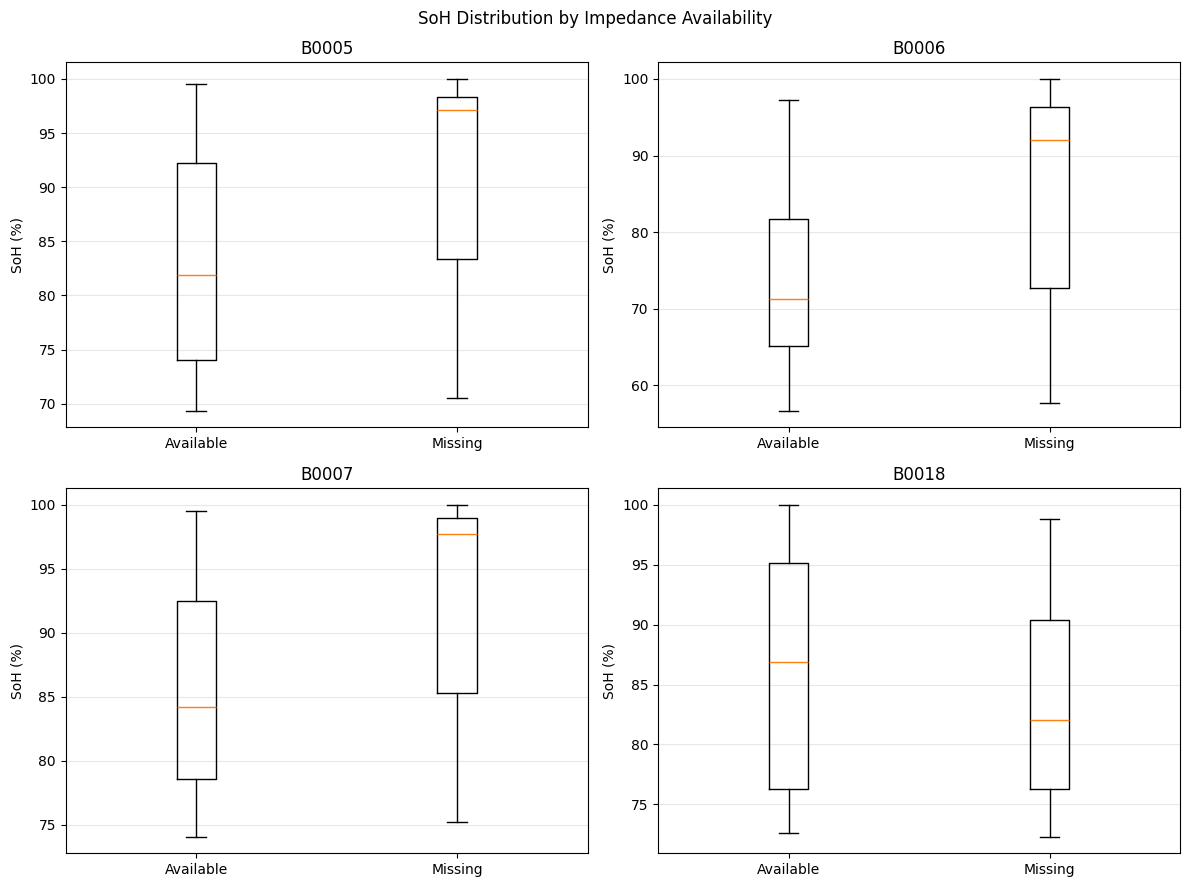

In [117]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, battery_id in zip(axes.flatten(), battery_ids):

    battery_data = combined_df[
        combined_df["battery_id"] == battery_id
    ]

    matched = battery_data.loc[
        battery_data["impedance_available"] == 1,
        "SoH_percent"
    ]

    unmatched = battery_data.loc[
        battery_data["impedance_available"] == 0,
        "SoH_percent"
    ]

    ax.boxplot(
        [matched, unmatched],
        tick_labels=["Available", "Missing"]
    )

    ax.set_title(battery_id)
    ax.set_ylabel("SoH (%)")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("SoH Distribution by Impedance Availability")
plt.tight_layout()
plt.show()

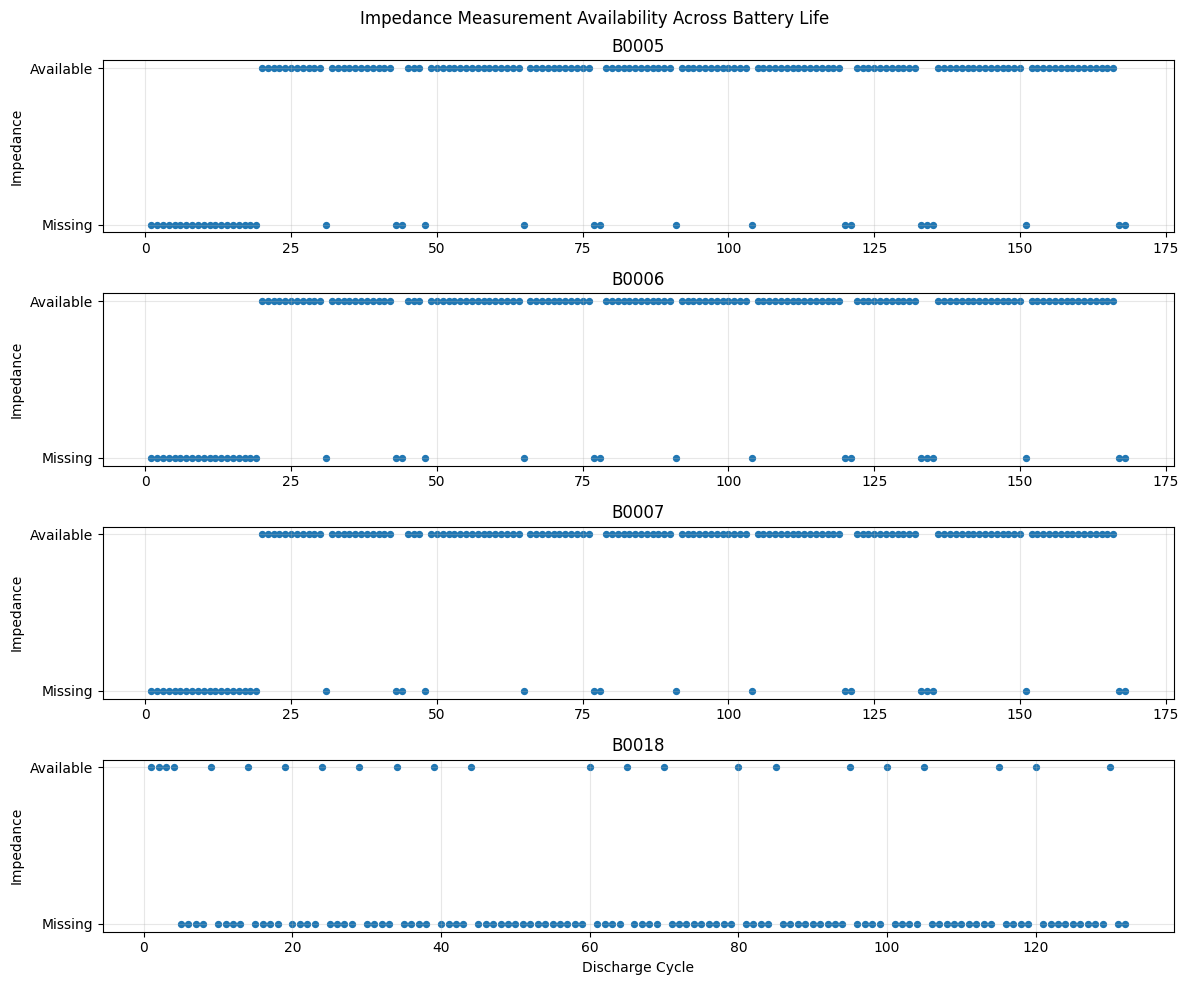

In [118]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=False)

for ax, battery_id in zip(axes, battery_ids):

    df = combined_df[
        combined_df["battery_id"] == battery_id
    ].copy()

    ax.scatter(
        range(1, len(df) + 1),
        df["impedance_available"],
        s=18
    )

    ax.set_title(battery_id)
    ax.set_ylabel("Impedance")
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Missing", "Available"])
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Discharge Cycle")

plt.suptitle("Impedance Measurement Availability Across Battery Life")
plt.tight_layout()
plt.show()

In [119]:
# Dataset A: all discharge cycles
model_dataset_A = combined_df.copy()

# Dataset B: only cycles with valid impedance measurements
model_dataset_B = combined_df[
    combined_df["impedance_available"] == 1
].copy()

# Reset indices
model_dataset_A = model_dataset_A.reset_index(drop=True)
model_dataset_B = model_dataset_B.reset_index(drop=True)

# Verify dataset sizes
print("Dataset A — Voltage and Temperature")
print("Shape:", model_dataset_A.shape)

print("\nDataset B — Voltage, Temperature and Impedance")
print("Shape:", model_dataset_B.shape)

print("\nObservations per battery in Dataset B:")
print(model_dataset_B.groupby("battery_id").size())

# Verify no missing impedance values in Dataset B
print(
    "\nMissing Re values:",
    model_dataset_B["Re"].isna().sum()
)

print(
    "Missing Rct values:",
    model_dataset_B["Rct"].isna().sum()
)

Dataset A — Voltage and Temperature
Shape: (636, 20)

Dataset B — Voltage, Temperature and Impedance
Shape: (419, 20)

Observations per battery in Dataset B:
battery_id
B0005    132
B0006    132
B0007    132
B0018     23
dtype: int64

Missing Re values: 0
Missing Rct values: 0


In [120]:
# Define the input features

features_A = [
    "voltage_mean",
    "voltage_min",
    "voltage_max",
    "current_mean",
    "temperature_mean",
    "temperature_max",
    "temperature_rise"
]

features_B = features_A + ["Re", "Rct"]


# Prepare Leave-One-Battery-Out datasets

loso_datasets = {}

for test_battery in battery_ids:

    # Dataset A: all discharge observations from other batteries
    train_A = model_dataset_A[
        model_dataset_A["battery_id"] != test_battery
    ].copy()

    # Dataset B: impedance-available observations from other batteries
    train_B = model_dataset_B[
        model_dataset_B["battery_id"] != test_battery
    ].copy()

    # Use the same matched test observations for both models
    test_data = model_dataset_B[
        model_dataset_B["battery_id"] == test_battery
    ].copy()

    loso_datasets[test_battery] = {
        "train_A": train_A,
        "train_B": train_B,
        "test": test_data
    }

    print(f"\nTest battery: {test_battery}")
    print("Dataset A training observations:", len(train_A))
    print("Dataset B training observations:", len(train_B))
    print("Common test observations:", len(test_data))


Test battery: B0005
Dataset A training observations: 468
Dataset B training observations: 287
Common test observations: 132

Test battery: B0006
Dataset A training observations: 468
Dataset B training observations: 287
Common test observations: 132

Test battery: B0007
Dataset A training observations: 468
Dataset B training observations: 287
Common test observations: 132

Test battery: B0018
Dataset A training observations: 504
Dataset B training observations: 396
Common test observations: 23


In [121]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = []

for test_battery in battery_ids:

    datasets = loso_datasets[test_battery]

    # Training data
    train_A = datasets["train_A"]
    train_B = datasets["train_B"]

    # Common test data
    test_data = datasets["test"]

    y_train_A = train_A["SoH_percent"]
    y_train_B = train_B["SoH_percent"]
    y_test = test_data["SoH_percent"]

    # Define models
    model_A = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1))
    ])

    model_B = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1))
    ])

    # Train Model A: voltage and temperature
    model_A.fit(train_A[features_A], y_train_A)

    # Train Model B: voltage, temperature and impedance
    model_B.fit(train_B[features_B], y_train_B)

    # Predictions on the same held-out battery observations
    predictions_A = model_A.predict(test_data[features_A])
    predictions_B = model_B.predict(test_data[features_B])

    # Calculate evaluation metrics
    for model_name, predictions in [
        ("Ridge - Voltage & Temperature", predictions_A),
        ("Ridge - With Impedance", predictions_B)
    ]:

        results.append({
            "test_battery": test_battery,
            "model": model_name,
            "observations": len(y_test),
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_test, predictions)
            ),
            "R2": r2_score(y_test, predictions)
        })

# Create results table
loso_results = pd.DataFrame(results)

print("Leave-One-Battery-Out Results:")
display(
    loso_results.round(4)
)

Leave-One-Battery-Out Results:


,test_battery,model,observations,MAE,RMSE,R2
0,B0005,Ridge - Voltage & Temperature,132,1.3290,1.6489,0.9705
1,B0005,Ridge - With Impedance,132,1.7044,2.0615,0.9539
2,B0006,Ridge - Voltage & Temperature,132,3.2029,3.9560,0.8621
3,B0006,Ridge - With Impedance,132,2.8362,3.6431,0.8831
4,B0007,Ridge - Voltage & Temperature,132,3.6938,4.0568,0.7314
5,B0007,Ridge - With Impedance,132,1.3230,1.7468,0.9502
6,B0018,Ridge - Voltage & Temperature,23,2.1462,2.4595,0.9356
7,B0018,Ridge - With Impedance,23,4.1715,5.2144,0.7105


In [122]:
results_fair = []

for test_battery in battery_ids:

    # Use the same impedance-available training observations
    # for both models
    train_data = model_dataset_B[
        model_dataset_B["battery_id"] != test_battery
    ].copy()

    # Same held-out test observations
    test_data = model_dataset_B[
        model_dataset_B["battery_id"] == test_battery
    ].copy()

    y_train = train_data["SoH_percent"]
    y_test = test_data["SoH_percent"]

    # Model A: voltage and temperature
    model_A = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1))
    ])

    # Model B: voltage, temperature and impedance
    model_B = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1))
    ])

    model_A.fit(train_data[features_A], y_train)
    model_B.fit(train_data[features_B], y_train)

    predictions_A = model_A.predict(test_data[features_A])
    predictions_B = model_B.predict(test_data[features_B])

    for model_name, predictions in [
        ("Voltage & Temperature", predictions_A),
        ("Voltage, Temperature & Impedance", predictions_B)
    ]:

        results_fair.append({
            "test_battery": test_battery,
            "model": model_name,
            "observations": len(y_test),
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_test, predictions)
            ),
            "R2": r2_score(y_test, predictions)
        })

fair_results_df = pd.DataFrame(results_fair)

display(fair_results_df.round(4))

,test_battery,model,observations,MAE,RMSE,R2
0,B0005,Voltage & Temperature,132,1.4376,1.9930,0.9569
1,B0005,"Voltage, Temperature & Impedance",132,1.7044,2.0615,0.9539
2,B0006,Voltage & Temperature,132,2.9777,3.9432,0.8630
3,B0006,"Voltage, Temperature & Impedance",132,2.8362,3.6431,0.8831
4,B0007,Voltage & Temperature,132,3.6999,4.4348,0.6790
5,B0007,"Voltage, Temperature & Impedance",132,1.3230,1.7468,0.9502
6,B0018,Voltage & Temperature,23,2.5204,3.0047,0.9039
7,B0018,"Voltage, Temperature & Impedance",23,4.1715,5.2144,0.7105


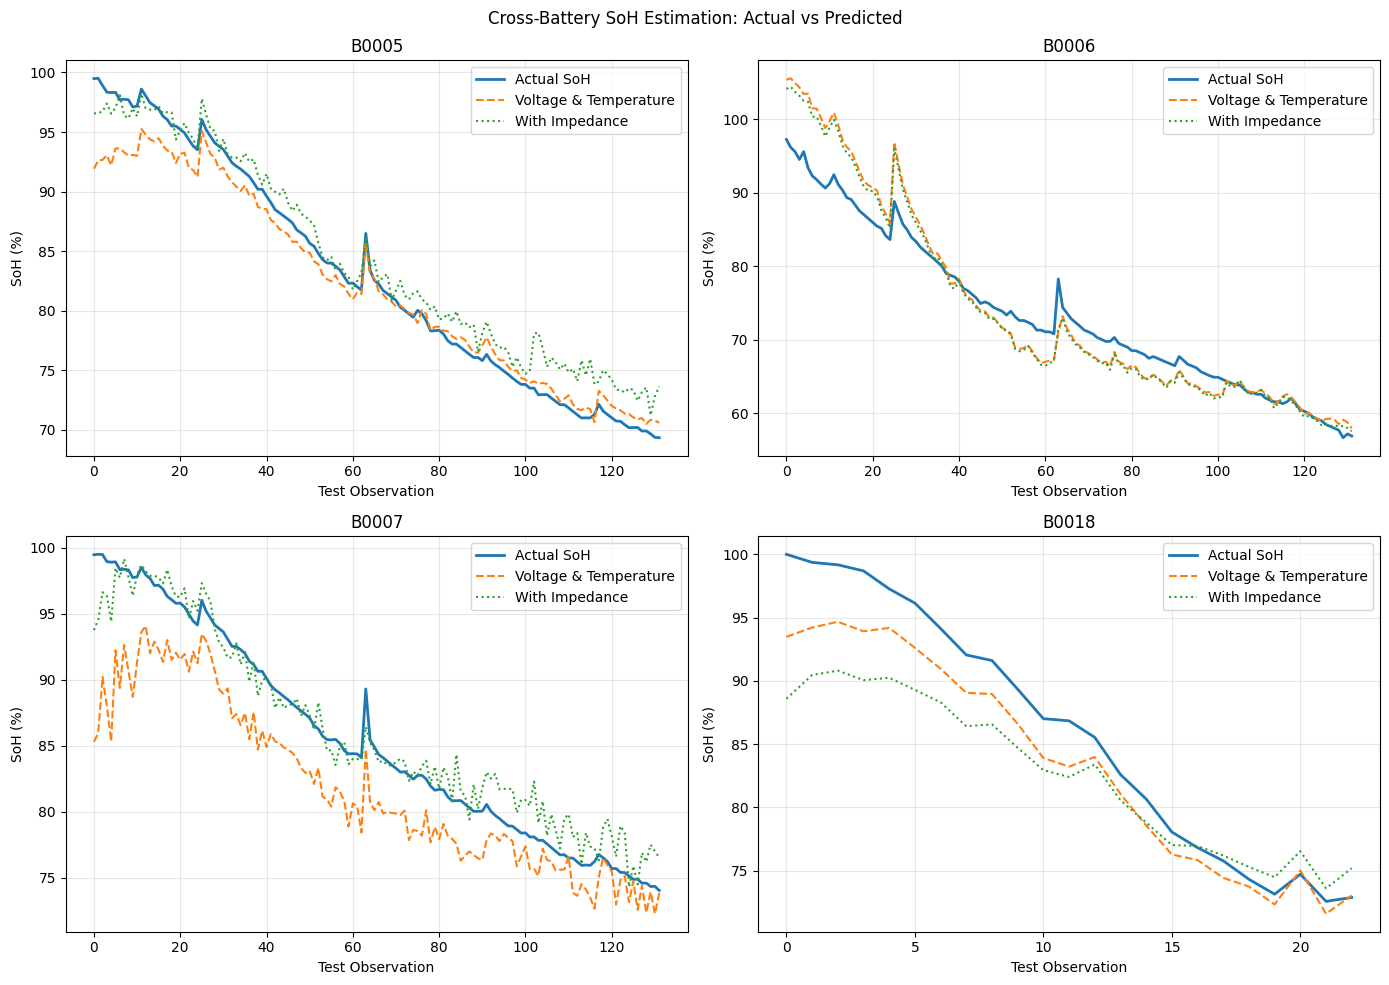

In [123]:
prediction_results = {}

for test_battery in battery_ids:

    train_data = model_dataset_B[
        model_dataset_B["battery_id"] != test_battery
    ].copy()

    test_data = model_dataset_B[
        model_dataset_B["battery_id"] == test_battery
    ].copy()

    y_train = train_data["SoH_percent"]
    y_test = test_data["SoH_percent"]

    # Model A: voltage and temperature
    model_A = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1))
    ])

    # Model B: voltage, temperature and impedance
    model_B = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1))
    ])

    model_A.fit(train_data[features_A], y_train)
    model_B.fit(train_data[features_B], y_train)

    predictions_A = model_A.predict(test_data[features_A])
    predictions_B = model_B.predict(test_data[features_B])

    prediction_results[test_battery] = pd.DataFrame({
        "actual_SoH": y_test.to_numpy(),
        "predicted_A": predictions_A,
        "predicted_B": predictions_B
    }).reset_index(drop=True)


# Plot predictions for each battery
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, battery_id in zip(axes.flatten(), battery_ids):

    results = prediction_results[battery_id]

    ax.plot(
        results["actual_SoH"].values,
        label="Actual SoH",
        linewidth=2
    )

    ax.plot(
        results["predicted_A"].values,
        label="Voltage & Temperature",
        linestyle="--"
    )

    ax.plot(
        results["predicted_B"].values,
        label="With Impedance",
        linestyle=":"
    )

    ax.set_title(battery_id)
    ax.set_xlabel("Test Observation")
    ax.set_ylabel("SoH (%)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Cross-Battery SoH Estimation: Actual vs Predicted")
plt.tight_layout()
plt.show()

In [124]:
bias_results = []

for battery_id in battery_ids:

    results = prediction_results[battery_id]

    for model_name, prediction_column in [
        ("Voltage & Temperature", "predicted_A"),
        ("With Impedance", "predicted_B")
    ]:

        errors = (
            results[prediction_column] -
            results["actual_SoH"]
        )

        bias_results.append({
            "battery": battery_id,
            "model": model_name,
            "mean_error": errors.mean(),
            "median_error": errors.median(),
            "mean_absolute_error": errors.abs().mean(),
            "maximum_absolute_error": errors.abs().max()
        })

bias_df = pd.DataFrame(bias_results)

display(bias_df.round(3))

,battery,model,mean_error,median_error,mean_absolute_error,maximum_absolute_error
0,B0005,Voltage & Temperature,-0.785,-0.506,1.438,7.575
1,B0005,With Impedance,1.382,1.454,1.704,5.209
2,B0006,Voltage & Temperature,0.517,-0.094,2.978,10.077
3,B0006,With Impedance,0.081,-0.563,2.836,8.959
4,B0007,Voltage & Temperature,-3.698,-3.637,3.700,14.157
5,B0007,With Impedance,0.557,0.499,1.323,5.702
6,B0018,Voltage & Temperature,-2.480,-2.646,2.520,6.525
7,B0018,With Impedance,-3.474,-4.064,4.172,11.421


In [125]:
baseline_results = []

for test_battery in battery_ids:

    # Same training and test population as the fair experiment
    train_data = model_dataset_B[
        model_dataset_B["battery_id"] != test_battery
    ].copy()

    test_data = model_dataset_B[
        model_dataset_B["battery_id"] == test_battery
    ].copy()

    y_test = test_data["SoH_percent"]

    # Baseline: predict the training-set mean SoH
    baseline_prediction = np.full(
        len(test_data),
        train_data["SoH_percent"].mean()
    )

    # Evaluate baseline
    baseline_results.append({
        "battery": test_battery,
        "training_mean_SoH": train_data["SoH_percent"].mean(),
        "baseline_MAE": mean_absolute_error(
            y_test, baseline_prediction
        ),
        "baseline_RMSE": np.sqrt(
            mean_squared_error(y_test, baseline_prediction)
        ),
        "baseline_R2": r2_score(
            y_test, baseline_prediction
        )
    })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df.round(4))

,battery,training_mean_SoH,baseline_MAE,baseline_RMSE,baseline_R2
0,B0005,80.0140,8.4742,10.0599,-0.0989
1,B0006,84.4029,13.2784,15.2520,-1.0492
2,B0007,78.8832,7.9272,10.2438,-0.7125
3,B0018,80.6706,9.4543,11.0734,-0.3057


In [126]:
# Merge baseline and Ridge results
comparison_df = fair_results_df.merge(
    baseline_df[["battery", "baseline_MAE"]],
    left_on="test_battery",
    right_on="battery"
)

# Calculate percentage improvement
comparison_df["improvement_vs_baseline_%"] = (
    (comparison_df["baseline_MAE"] - comparison_df["MAE"])
    / comparison_df["baseline_MAE"]
) * 100

# Display relevant columns
display(
    comparison_df[
        [
            "test_battery",
            "model",
            "baseline_MAE",
            "MAE",
            "improvement_vs_baseline_%"
        ]
    ].round(2)
)

# Calculate observation-weighted overall MAE
print("\nOverall weighted MAE:")

for model_name, group in comparison_df.groupby("model"):

    weighted_mae = np.average(
        group["MAE"],
        weights=group["observations"]
    )

    print(f"{model_name}: {weighted_mae:.3f}")

weighted_baseline = np.average(
    baseline_df["baseline_MAE"],
    weights=[132, 132, 132, 23]
)

print(f"Baseline: {weighted_baseline:.3f}")

,test_battery,model,baseline_MAE,MAE,improvement_vs_baseline_%
0,B0005,Voltage & Temperature,8.47,1.44,83.04
1,B0005,"Voltage, Temperature & Impedance",8.47,1.70,79.89
2,B0006,Voltage & Temperature,13.28,2.98,77.58
3,B0006,"Voltage, Temperature & Impedance",13.28,2.84,78.64
4,B0007,Voltage & Temperature,7.93,3.70,53.33
5,B0007,"Voltage, Temperature & Impedance",7.93,1.32,83.31
6,B0018,Voltage & Temperature,9.45,2.52,73.34
7,B0018,"Voltage, Temperature & Impedance",9.45,4.17,55.88



Overall weighted MAE:
Voltage & Temperature: 2.695
Voltage, Temperature & Impedance: 2.076
Baseline: 9.869


In [127]:
from sklearn.inspection import permutation_importance

importance_results = []

for test_battery in battery_ids:

    train_data = model_dataset_B[
        model_dataset_B["battery_id"] != test_battery
    ].copy()

    test_data = model_dataset_B[
        model_dataset_B["battery_id"] == test_battery
    ].copy()

    model_B = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1))
    ])

    model_B.fit(
        train_data[features_B],
        train_data["SoH_percent"]
    )

    # Permutation importance on the held-out battery
    importance = permutation_importance(
        model_B,
        test_data[features_B],
        test_data["SoH_percent"],
        scoring="neg_mean_absolute_error",
        n_repeats=30,
        random_state=42
    )

    for feature, mean_importance, std_importance in zip(
        features_B,
        importance.importances_mean,
        importance.importances_std
    ):

        importance_results.append({
            "battery": test_battery,
            "feature": feature,
            "importance": mean_importance,
            "std": std_importance
        })

importance_df = pd.DataFrame(importance_results)

# Display results
display(
    importance_df.pivot(
        index="feature",
        columns="battery",
        values="importance"
    ).round(4)
)

battery,B0005,B0006,B0007,B0018
feature,,,,
Rct,0.1891,0.7386,2.1203,0.1749
Re,2.3545,-0.2712,4.7985,0.3625
current_mean,3.3408,1.6403,2.2112,2.1529
temperature_max,4.4971,0.5105,3.6022,2.5939
temperature_mean,2.2931,2.6465,2.1349,0.5318
temperature_rise,0.0807,-0.4328,0.0315,-0.0910
voltage_max,-0.0139,0.0083,0.0096,0.0191
voltage_mean,1.9614,4.1190,1.8071,0.9596
voltage_min,0.0249,-0.0253,0.0776,-0.0169


In [128]:
ablation_results = []

feature_sets = {
    "Voltage & Temperature": features_A,
    "Voltage & Temperature + Re": features_A + ["Re"],
    "Voltage & Temperature + Rct": features_A + ["Rct"],
    "Voltage & Temperature + Re + Rct": features_B
}

for test_battery in battery_ids:

    train_data = model_dataset_B[
        model_dataset_B["battery_id"] != test_battery
    ].copy()

    test_data = model_dataset_B[
        model_dataset_B["battery_id"] == test_battery
    ].copy()

    y_train = train_data["SoH_percent"]
    y_test = test_data["SoH_percent"]

    for model_name, selected_features in feature_sets.items():

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=1))
        ])

        model.fit(
            train_data[selected_features],
            y_train
        )

        predictions = model.predict(
            test_data[selected_features]
        )

        ablation_results.append({
            "battery": test_battery,
            "model": model_name,
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_test, predictions)
            ),
            "R2": r2_score(y_test, predictions)
        })

ablation_df = pd.DataFrame(ablation_results)

display(
    ablation_df.pivot(
        index="model",
        columns="battery",
        values="MAE"
    ).round(3)
)

battery,B0005,B0006,B0007,B0018
model,,,,
Voltage & Temperature,1.438,2.978,3.700,2.520
Voltage & Temperature + Rct,1.274,2.950,2.752,4.802
Voltage & Temperature + Re,1.641,2.781,0.967,3.799
Voltage & Temperature + Re + Rct,1.704,2.836,1.323,4.172


In [129]:
# Observation-weighted MAE across all held-out batteries

summary_ablation = (
    ablation_df
    .groupby("model")
    .apply(
        lambda group: np.average(
            group["MAE"],
            weights=[
                132 if b != "B0018" else 23
                for b in group["battery"]
            ]
        ),
        include_groups=False
    )
    .reset_index(name="weighted_MAE")
    .sort_values("weighted_MAE")
)

display(summary_ablation.round(4))

,model,weighted_MAE
2,Voltage & Temperature + Re,1.9060
3,Voltage & Temperature + Re + Rct,2.0762
1,Voltage & Temperature + Rct,2.4613
0,Voltage & Temperature,2.6949


In [130]:
re_correlation_results = []

for battery_id in battery_ids:

    df = model_dataset_B[
        model_dataset_B["battery_id"] == battery_id
    ]

    pearson_corr = df["Re"].corr(
        df["SoH_percent"],
        method="pearson"
    )

    spearman_corr = df["Re"].corr(
        df["SoH_percent"],
        method="spearman"
    )

    re_correlation_results.append({
        "battery": battery_id,
        "observations": len(df),
        "Pearson_Re_SoH": pearson_corr,
        "Spearman_Re_SoH": spearman_corr
    })

re_correlation_df = pd.DataFrame(
    re_correlation_results
)

display(re_correlation_df.round(4))

,battery,observations,Pearson_Re_SoH,Spearman_Re_SoH
0,B0005,132,-0.8833,-0.8111
1,B0006,132,-0.9733,-0.9755
2,B0007,132,-0.9534,-0.9673
3,B0018,23,-0.6565,-0.6423


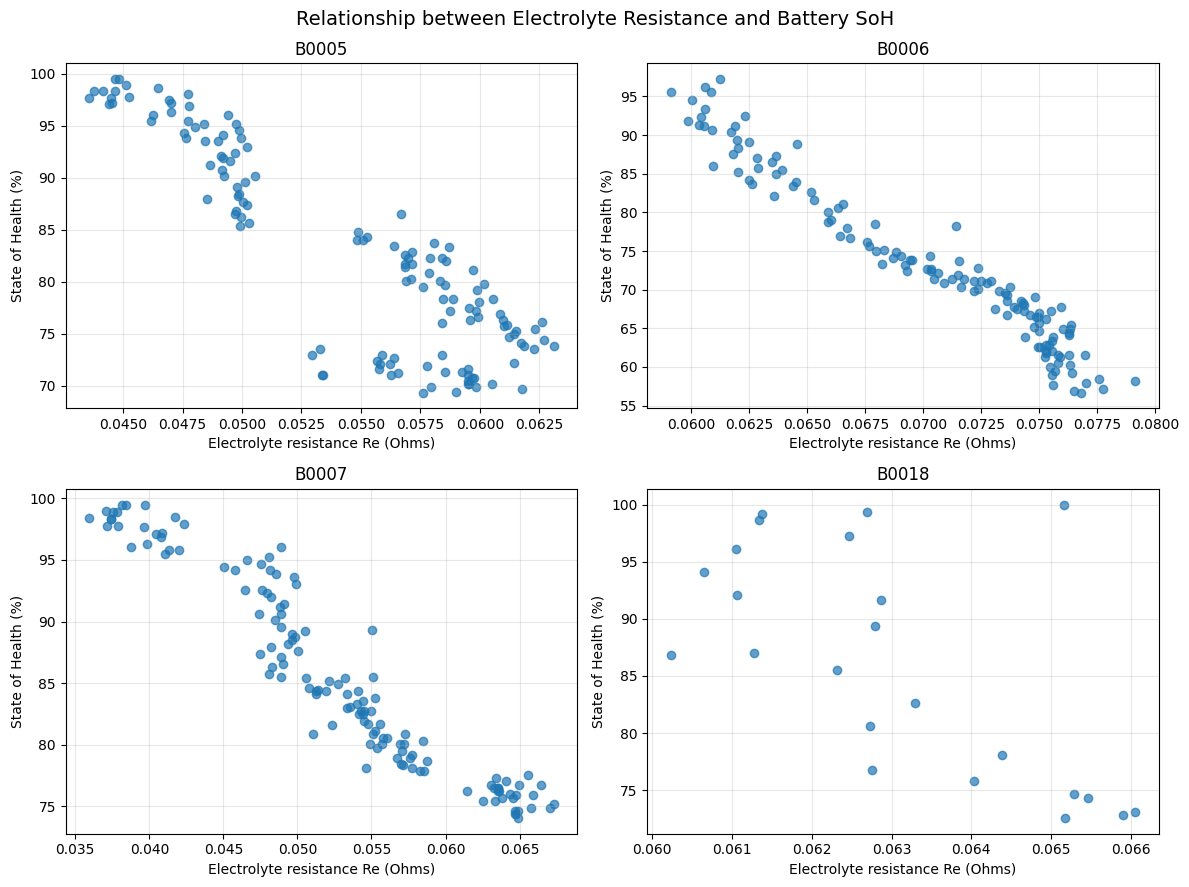

In [131]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, battery_id in zip(axes.flatten(), battery_ids):

    df = model_dataset_B[
        model_dataset_B["battery_id"] == battery_id
    ]

    ax.scatter(
        df["Re"],
        df["SoH_percent"],
        alpha=0.7
    )

    ax.set_title(battery_id)
    ax.set_xlabel("Electrolyte resistance Re (Ohms)")
    ax.set_ylabel("State of Health (%)")
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Relationship between Electrolyte Resistance and Battery SoH",
    fontsize=14
)

plt.tight_layout()
plt.show()

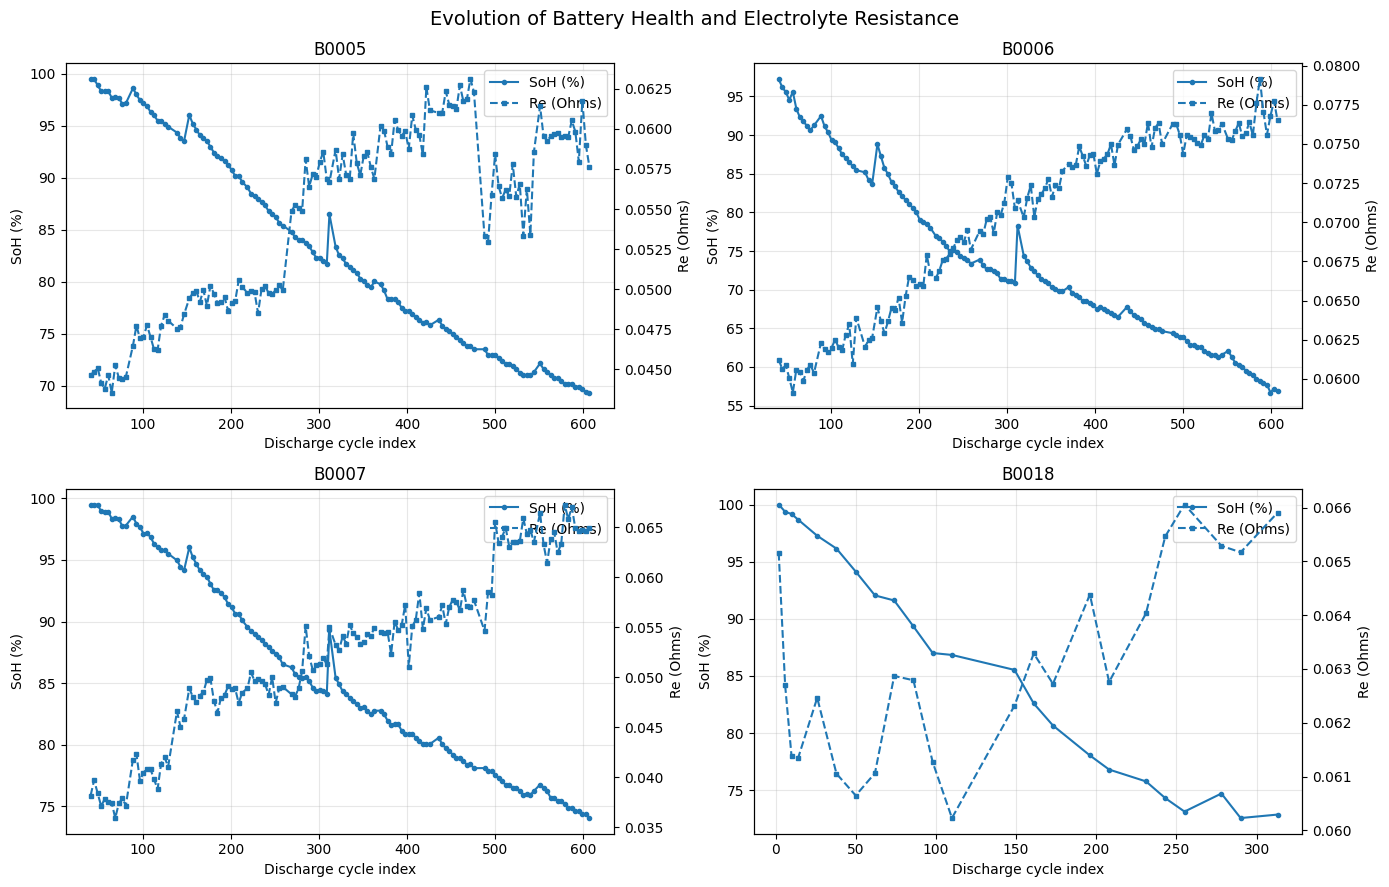

In [132]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, battery_id in zip(axes.flatten(), battery_ids):

    df = (
        model_dataset_B[
            model_dataset_B["battery_id"] == battery_id
        ]
        .sort_values("record_index")
    )

    ax2 = ax.twinx()

    line1 = ax.plot(
        df["record_index"],
        df["SoH_percent"],
        marker="o",
        markersize=3,
        label="SoH (%)"
    )

    line2 = ax2.plot(
        df["record_index"],
        df["Re"],
        marker="s",
        markersize=3,
        linestyle="--",
        label="Re (Ohms)"
    )

    ax.set_title(battery_id)
    ax.set_xlabel("Discharge cycle index")
    ax.set_ylabel("SoH (%)")
    ax2.set_ylabel("Re (Ohms)")

    lines = line1 + line2
    ax.legend(lines, [line.get_label() for line in lines],
              loc="best")

    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Evolution of Battery Health and Electrolyte Resistance",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [133]:
from scipy.stats import pearsonr

adjusted_correlations_corrected = []

for battery_id in battery_ids:

    # Select impedance-matched observations
    df = (
        model_dataset_B[
            model_dataset_B["battery_id"] == battery_id
        ]
        .sort_values("record_index")
        .copy()
    )

    # Use the original discharge-cycle indices
    cycle_number = df["record_index"].to_numpy()

    soh = df["SoH_percent"].to_numpy()
    re = df["Re"].to_numpy()

    # Fit linear trends against the actual cycle indices
    soh_trend = np.polyfit(cycle_number, soh, 1)
    re_trend = np.polyfit(cycle_number, re, 1)

    # Calculate residuals (variations not explained by cycle number)
    soh_residuals = (
        soh - np.polyval(soh_trend, cycle_number)
    )

    re_residuals = (
        re - np.polyval(re_trend, cycle_number)
    )

    # Calculate correlation between residuals
    corr, p_value = pearsonr(
        soh_residuals,
        re_residuals
    )

    adjusted_correlations_corrected.append({
        "battery": battery_id,
        "observations": len(df),
        "adjusted_correlation": corr,
        "p_value": p_value
    })

# Display results
adjusted_corr_corrected_df = pd.DataFrame(
    adjusted_correlations_corrected
)

display(adjusted_corr_corrected_df.round(4))

,battery,observations,adjusted_correlation,p_value
0,B0005,132,-0.5157,0.0000
1,B0006,132,-0.5437,0.0000
2,B0007,132,0.0513,0.5589
3,B0018,23,0.3457,0.1061


In [134]:
import statsmodels.api as sm

regression_results = []

for battery_id in battery_ids:

    df = (
        model_dataset_B[
            model_dataset_B["battery_id"] == battery_id
        ]
        .sort_values("record_index")
        .copy()
    )

    y = df["SoH_percent"]

    # Model 1: Cycle number only
    X1 = sm.add_constant(
        df[["record_index"]]
    )
    model_1 = sm.OLS(y, X1).fit()

    # Model 2: Cycle number + Re
    X2 = sm.add_constant(
        df[["record_index", "Re"]]
    )
    model_2 = sm.OLS(y, X2).fit()

    regression_results.append({
        "battery": battery_id,
        "observations": len(df),
        "R2_cycle_only": model_1.rsquared,
        "R2_cycle_plus_Re": model_2.rsquared,
        "R2_improvement": (
            model_2.rsquared - model_1.rsquared
        ),
        "Re_coefficient": model_2.params["Re"],
        "Re_p_value": model_2.pvalues["Re"]
    })

regression_df = pd.DataFrame(regression_results)

display(regression_df.round(4))

,battery,observations,R2_cycle_only,R2_cycle_plus_Re,R2_improvement,Re_coefficient,Re_p_value
0,B0005,132,0.9815,0.9864,0.0049,-230.0183,0.0000
1,B0006,132,0.9543,0.9678,0.0135,-854.2126,0.0000
2,B0007,132,0.9754,0.9755,0.0001,30.2034,0.5604
3,B0018,23,0.9723,0.9757,0.0033,446.4740,0.1150


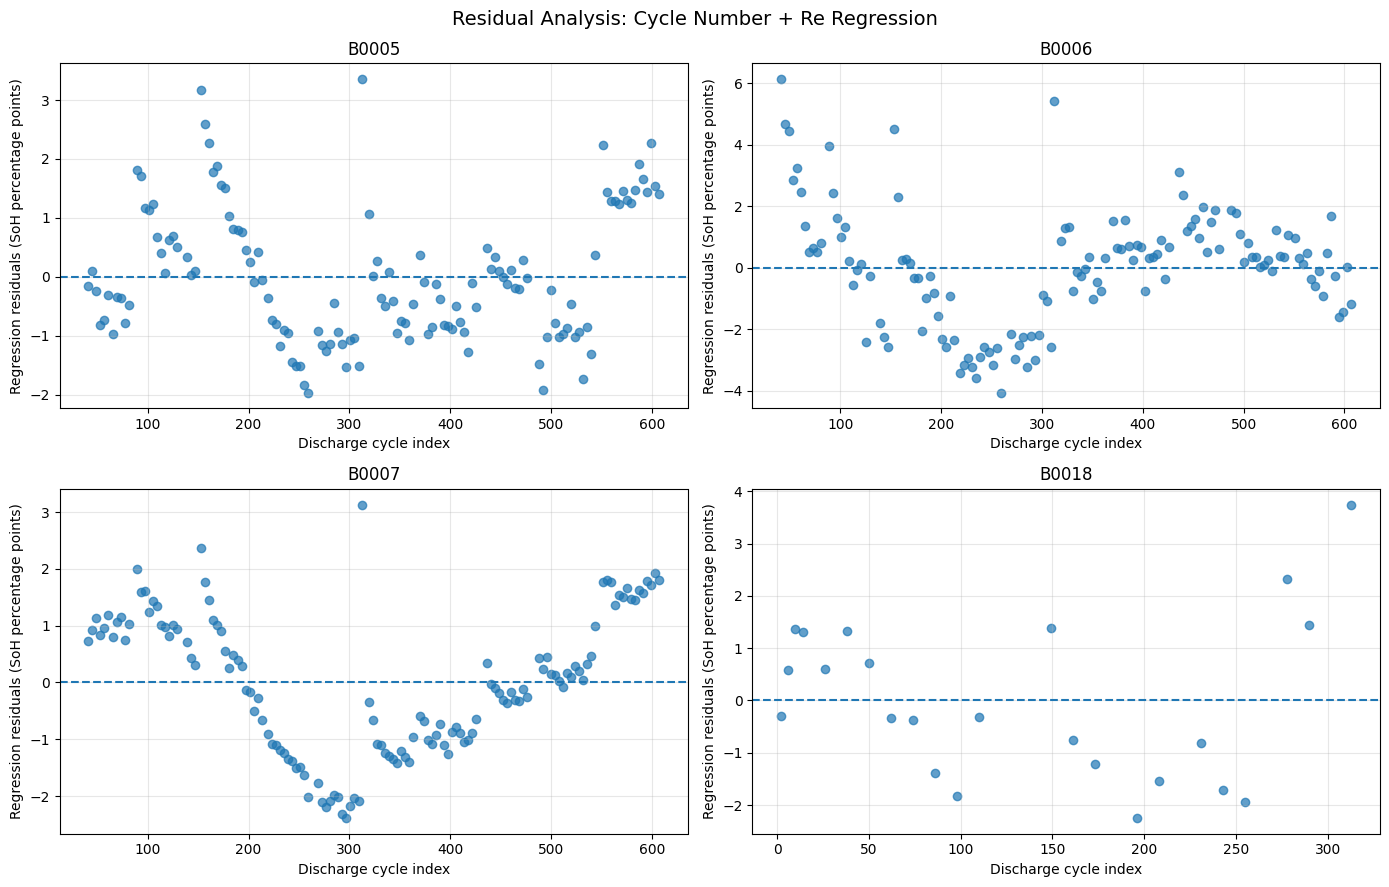

In [135]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, battery_id in zip(axes.flatten(), battery_ids):

    df = (
        model_dataset_B[
            model_dataset_B["battery_id"] == battery_id
        ]
        .sort_values("record_index")
        .copy()
    )

    X = sm.add_constant(
        df[["record_index", "Re"]]
    )

    y = df["SoH_percent"]

    model = sm.OLS(y, X).fit()

    residuals = model.resid

    ax.scatter(
        df["record_index"],
        residuals,
        alpha=0.7
    )

    ax.axhline(0, linestyle="--")

    ax.set_title(battery_id)
    ax.set_xlabel("Discharge cycle index")
    ax.set_ylabel("Regression residuals (SoH percentage points)")
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Residual Analysis: Cycle Number + Re Regression",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [136]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

nonlinear_results = []

for battery_id in battery_ids:

    df = (
        model_dataset_B[
            model_dataset_B["battery_id"] == battery_id
        ]
        .sort_values("record_index")
        .copy()
    )

    X = df[["record_index", "Re"]]
    y = df["SoH_percent"]

    # Linear model
    linear_model = LinearRegression()
    linear_model.fit(X, y)

    pred_linear = linear_model.predict(X)

    # Polynomial model (degree 2)
    polynomial_model = Pipeline([
        ("poly", PolynomialFeatures(
            degree=2,
            include_bias=False
        )),
        ("regression", LinearRegression())
    ])

    polynomial_model.fit(X, y)

    pred_polynomial = polynomial_model.predict(X)

    nonlinear_results.append({
        "battery": battery_id,
        "Linear_MAE": mean_absolute_error(y, pred_linear),
        "Polynomial_MAE": mean_absolute_error(y, pred_polynomial),
        "Linear_R2": r2_score(y, pred_linear),
        "Polynomial_R2": r2_score(y, pred_polynomial)
    })

nonlinear_df = pd.DataFrame(nonlinear_results)

display(nonlinear_df.round(4))

,battery,Linear_MAE,Polynomial_MAE,Linear_R2,Polynomial_R2
0,B0005,0.9107,0.6354,0.9864,0.9926
1,B0006,1.4445,1.0019,0.9678,0.9836
2,B0007,1.0433,0.4468,0.9755,0.9934
3,B0018,1.2871,0.6698,0.9757,0.9921


In [137]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score

temporal_results = []

for battery_id in battery_ids:

    df = (
        model_dataset_B[
            model_dataset_B["battery_id"] == battery_id
        ]
        .sort_values("record_index")
        .copy()
    )

    # Chronological 70/30 split
    split_index = int(len(df) * 0.70)

    train = df.iloc[:split_index]
    test = df.iloc[split_index:]

    X_train = train[["record_index", "Re"]]
    X_test = test[["record_index", "Re"]]

    y_train = train["SoH_percent"]
    y_test = test["SoH_percent"]

    # Linear model
    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)

    pred_linear = linear_model.predict(X_test)

    # Polynomial model
    polynomial_model = Pipeline([
        ("poly", PolynomialFeatures(
            degree=2,
            include_bias=False
        )),
        ("regression", LinearRegression())
    ])

    polynomial_model.fit(X_train, y_train)

    pred_polynomial = polynomial_model.predict(X_test)

    temporal_results.append({
        "battery": battery_id,
        "train_observations": len(train),
        "test_observations": len(test),
        "Linear_MAE": mean_absolute_error(
            y_test, pred_linear
        ),
        "Polynomial_MAE": mean_absolute_error(
            y_test, pred_polynomial
        ),
        "Linear_R2": r2_score(
            y_test, pred_linear
        ),
        "Polynomial_R2": r2_score(
            y_test, pred_polynomial
        )
    })

temporal_df = pd.DataFrame(temporal_results)

display(temporal_df.round(4))

,battery,train_observations,test_observations,Linear_MAE,Polynomial_MAE,Linear_R2,Polynomial_R2
0,B0005,92,40,2.9942,8.4386,-2.6401,-28.9240
1,B0006,92,40,3.1757,4.0541,-0.2180,-1.6735
2,B0007,92,40,3.1378,0.6250,-3.2745,0.7801
3,B0018,16,7,2.8648,1.6498,-5.8137,-0.8191


In [138]:
distribution_results = []

for battery_id in battery_ids:

    df = (
        model_dataset_B[
            model_dataset_B["battery_id"] == battery_id
        ]
        .sort_values("record_index")
        .copy()
    )

    split_index = int(len(df) * 0.70)

    train = df.iloc[:split_index]
    test = df.iloc[split_index:]

    distribution_results.append({
        "battery": battery_id,
        "train_SoH_min": train["SoH_percent"].min(),
        "train_SoH_max": train["SoH_percent"].max(),
        "test_SoH_min": test["SoH_percent"].min(),
        "test_SoH_max": test["SoH_percent"].max()
    })

distribution_df = pd.DataFrame(distribution_results)

display(distribution_df.round(2))

,battery,train_SoH_min,train_SoH_max,test_SoH_min,test_SoH_max
0,B0005,75.82,99.51,69.35,75.79
1,B0006,66.49,97.26,56.69,67.23
2,B0007,80.04,99.49,74.06,80.04
3,B0018,78.05,100.00,72.57,76.81


In [139]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

comparison_results = []

for battery_id in battery_ids:

    df = (
        model_dataset_B[
            model_dataset_B["battery_id"] == battery_id
        ]
        .sort_values("record_index")
        .copy()
    )

    split_index = int(len(df) * 0.70)

    train = df.iloc[:split_index]
    test = df.iloc[split_index:]

    y_train = train["SoH_percent"]
    y_test = test["SoH_percent"]

    # Model 1: Cycle only
    X1_train = train[["record_index"]]
    X1_test = test[["record_index"]]

    model_1 = LinearRegression()
    model_1.fit(X1_train, y_train)
    pred_1 = model_1.predict(X1_test)

    # Model 2: Cycle + Re
    X2_train = train[["record_index", "Re"]]
    X2_test = test[["record_index", "Re"]]

    model_2 = LinearRegression()
    model_2.fit(X2_train, y_train)
    pred_2 = model_2.predict(X2_test)

    # Model 3: Polynomial Cycle + Re
    model_3 = Pipeline([
        ("poly", PolynomialFeatures(
            degree=2,
            include_bias=False
        )),
        ("regression", LinearRegression())
    ])

    model_3.fit(X2_train, y_train)
    pred_3 = model_3.predict(X2_test)

    predictions = {
        "Cycle only": pred_1,
        "Cycle + Re": pred_2,
        "Polynomial": pred_3
    }

    for model_name, predictions_test in predictions.items():

        comparison_results.append({
            "battery": battery_id,
            "model": model_name,
            "MAE": mean_absolute_error(
                y_test, predictions_test
            ),
            "RMSE": np.sqrt(
                mean_squared_error(y_test, predictions_test)
            ),
            "R2": r2_score(
                y_test, predictions_test
            )
        })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.pivot(
        index="battery",
        columns="model",
        values="MAE"
    ).round(4)
)

model,Cycle + Re,Cycle only,Polynomial
battery,,,
B0005,2.9942,2.9301,8.4386
B0006,3.1757,5.1297,4.0541
B0007,3.1378,3.1091,0.6250
B0018,2.8648,3.2241,1.6498


In [140]:
# Number of test observations per battery
test_weights = {
    "B0005": 40,
    "B0006": 40,
    "B0007": 40,
    "B0018": 7
}

# Add observation counts
comparison_df["test_observations"] = (
    comparison_df["battery"].map(test_weights)
)

# Calculate overall model performance
overall_results = (
    comparison_df
    .groupby("model")
    .apply(
        lambda group: pd.Series({
            "weighted_MAE": np.average(
                group["MAE"],
                weights=group["test_observations"]
            ),
            "mean_battery_MAE": group["MAE"].mean(),
            "weighted_RMSE": np.sqrt(
                np.average(
                    group["RMSE"] ** 2,
                    weights=group["test_observations"]
                )
            ),
            "total_test_observations":
                group["test_observations"].sum()
        }),
        include_groups=False
    )
    .sort_values("weighted_MAE")
)

display(overall_results.round(4))

,weighted_MAE,mean_battery_MAE,weighted_RMSE,total_test_observations
model,,,,
Cycle + Re,3.0894,3.0431,3.3447,127.0
Cycle only,3.6955,3.5982,4.0590,127.0
Polynomial,4.2225,3.6919,6.0997,127.0


In [141]:
# Inspect the Cycle + Re model for each battery

selected_results = []

for battery_id in battery_ids:

    train_data = model_dataset_B[
        (model_dataset_B["battery_id"] == battery_id)
    ].copy()

    X = train_data[["record_index", "Re"]]
    y = train_data["SoH_percent"]

    model = LinearRegression()
    model.fit(X, y)

    selected_results.append({
        "battery": battery_id,
        "cycle_coefficient": model.coef_[0],
        "Re_coefficient": model.coef_[1],
        "intercept": model.intercept_
    })

coefficients_df = pd.DataFrame(selected_results)

display(coefficients_df.round(4))

,battery,cycle_coefficient,Re_coefficient,intercept
0,B0005,-0.0507,-230.0183,112.0089
1,B0006,-0.0353,-854.2126,144.8857
2,B0007,-0.0482,30.2034,99.5404
3,B0018,-0.1013,446.4740,71.4062


In [142]:
# Calculate coefficients using only the temporal training data

training_coefficients = []

for battery_id in battery_ids:

    battery_data = (
        model_dataset_B[
            model_dataset_B["battery_id"] == battery_id
        ]
        .sort_values("record_index")
        .copy()
    )

    split_index = int(len(battery_data) * 0.7)
    train_data = battery_data.iloc[:split_index]

    X_train = train_data[["record_index", "Re"]]
    y_train = train_data["SoH_percent"]

    model = LinearRegression()
    model.fit(X_train, y_train)

    training_coefficients.append({
        "battery": battery_id,
        "training_observations": len(train_data),
        "cycle_coefficient": model.coef_[0],
        "Re_coefficient": model.coef_[1],
        "intercept": model.intercept_
    })

training_coefficients_df = pd.DataFrame(training_coefficients)

display(training_coefficients_df.round(4))

,battery,training_observations,cycle_coefficient,Re_coefficient,intercept
0,B0005,92,-0.0652,9.1396,102.7982
1,B0006,92,-0.0534,-512.9446,125.8546
2,B0007,92,-0.0573,62.0117,99.8703
3,B0018,16,-0.1115,186.3776,88.2994


In [143]:
# Check correlation between cycle number and Re

cycle_re_correlations = []

for battery_id in battery_ids:

    battery_data = (
        model_dataset_B[
            model_dataset_B["battery_id"] == battery_id
        ]
        .sort_values("record_index")
        .copy()
    )

    split_index = int(len(battery_data) * 0.7)
    train_data = battery_data.iloc[:split_index]

    correlation = train_data[
        ["record_index", "Re"]
    ].corr().iloc[0, 1]

    cycle_re_correlations.append({
        "battery": battery_id,
        "training_observations": len(train_data),
        "cycle_Re_correlation": correlation
    })

cycle_re_corr_df = pd.DataFrame(cycle_re_correlations)

display(cycle_re_corr_df.round(4))

,battery,training_observations,cycle_Re_correlation
0,B0005,92,0.9629
1,B0006,92,0.9851
2,B0007,92,0.9391
3,B0018,16,0.2091


In [144]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF for each battery's training data

vif_results = []

for battery_id in battery_ids:

    battery_data = (
        model_dataset_B[
            model_dataset_B["battery_id"] == battery_id
        ]
        .sort_values("record_index")
        .copy()
    )

    split_index = int(len(battery_data) * 0.7)
    train_data = battery_data.iloc[:split_index]

    X = train_data[["record_index", "Re"]].copy()

    # Standardise variables for numerical stability
    X = (X - X.mean()) / X.std()

    vif_cycle = variance_inflation_factor(X.values, 0)
    vif_re = variance_inflation_factor(X.values, 1)

    vif_results.append({
        "battery": battery_id,
        "VIF_cycle": vif_cycle,
        "VIF_Re": vif_re
    })

vif_df = pd.DataFrame(vif_results)

display(vif_df.round(2))

,battery,VIF_cycle,VIF_Re
0,B0005,13.74,13.74
1,B0006,33.83,33.83
2,B0007,8.47,8.47
3,B0018,1.05,1.05


In [145]:
# Test whether resistance deviations add information
# beyond the general cycle-related resistance trend.

from sklearn.linear_model import LinearRegression

residual_results = []

for battery_id in battery_ids:

    battery_data = (
        model_dataset_B[
            model_dataset_B["battery_id"] == battery_id
        ]
        .sort_values("record_index")
        .copy()
    )

    split_index = int(len(battery_data) * 0.7)

    train_data = battery_data.iloc[:split_index].copy()
    test_data = battery_data.iloc[split_index:].copy()

    # Step 1: Estimate expected Re from cycle number
    resistance_trend = LinearRegression()

    resistance_trend.fit(
        train_data[["record_index"]],
        train_data["Re"]
    )

    # Step 2: Calculate resistance residuals
    train_data["Re_residual"] = (
        train_data["Re"] -
        resistance_trend.predict(train_data[["record_index"]])
    )

    test_data["Re_residual"] = (
        test_data["Re"] -
        resistance_trend.predict(test_data[["record_index"]])
    )

    # Step 3: Fit SoH models
    model_cycle = LinearRegression()
    model_residual = LinearRegression()

    model_cycle.fit(
        train_data[["record_index"]],
        train_data["SoH_percent"]
    )

    model_residual.fit(
        train_data[["record_index", "Re_residual"]],
        train_data["SoH_percent"]
    )

    # Step 4: Evaluate on the later observations
    pred_cycle = model_cycle.predict(
        test_data[["record_index"]]
    )

    pred_residual = model_residual.predict(
        test_data[["record_index", "Re_residual"]]
    )

    residual_results.append({
        "battery": battery_id,
        "test_observations": len(test_data),
        "Cycle_only_MAE": mean_absolute_error(
            test_data["SoH_percent"], pred_cycle
        ),
        "Cycle_plus_residual_Re_MAE": mean_absolute_error(
            test_data["SoH_percent"], pred_residual
        )
    })

residual_comparison_df = pd.DataFrame(residual_results)

display(residual_comparison_df.round(4))

,battery,test_observations,Cycle_only_MAE,Cycle_plus_residual_Re_MAE
0,B0005,40,2.9301,2.9942
1,B0006,40,5.1297,3.1757
2,B0007,40,3.1091,3.1378
3,B0018,7,3.2241,2.8648


In [146]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [147]:
import os

project_folder = "/content/drive/MyDrive/Battery_Digital_Twin"

results_folder = os.path.join(project_folder, "results")

os.makedirs(results_folder, exist_ok=True)

print("Project folder:", project_folder)
print("Results folder:", results_folder)
print("Folder created successfully!")

Project folder: /content/drive/MyDrive/Battery_Digital_Twin
Results folder: /content/drive/MyDrive/Battery_Digital_Twin/results
Folder created successfully!


In [148]:
import os

# Results to export
results_to_save = {
    "temporal_model_comparison": comparison_df,
    "overall_model_performance": overall_results,
    "full_data_coefficients": coefficients_df,
    "training_coefficients": training_coefficients_df,
    "cycle_Re_correlations": cycle_re_corr_df,
    "multicollinearity_VIF": vif_df,
    "residual_Re_comparison": residual_comparison_df
}

# Save each result as a CSV file
for filename, dataframe in results_to_save.items():
    filepath = os.path.join(
        results_folder,
        f"{filename}.csv"
    )
    dataframe.to_csv(filepath, index=True)
    print("Saved:", filename + ".csv")

print("\nAll modelling results exported successfully!")

Saved: temporal_model_comparison.csv
Saved: overall_model_performance.csv
Saved: full_data_coefficients.csv
Saved: training_coefficients.csv
Saved: cycle_Re_correlations.csv
Saved: multicollinearity_VIF.csv
Saved: residual_Re_comparison.csv

All modelling results exported successfully!


In [149]:
report = """
# Battery Digital Twin – Modelling Results

## 1. Dataset
- NASA Battery Aging Dataset
- Batteries: B0005, B0006, B0007, B0018
- Total discharge observations: 636
- Matched impedance observations: 419
- Health target: State of Health (SoH), calculated from
  discharge capacity relative to initial measured capacity.

## 2. Modelling objective
Investigate whether electrical and thermal indicators,
particularly impedance resistance (Re), provide useful
information for battery SoH estimation.

## 3. Temporal validation
A chronological 70/30 train-test split was used for
each battery.

| Model | Weighted MAE | Weighted RMSE |
|---|---:|---:|
| Cycle + Re | 3.0894 | 3.3447 |
| Cycle only | 3.6955 | 4.0590 |
| Polynomial | 4.2225 | 6.0997 |

Cycle + Re achieved a 16.4% reduction in weighted MAE
compared with Cycle only.

## 4. Multicollinearity
Training-set correlations between cycle number and Re:
- B0005: 0.9629
- B0006: 0.9851
- B0007: 0.9391
- B0018: 0.2091

VIF values:
- B0005: 13.74
- B0006: 33.83
- B0007: 8.47
- B0018: 1.05

These results indicate substantial multicollinearity
for the first three batteries.

## 5. Residual resistance experiment
Resistance was modelled as a function of cycle number.
The residual resistance was then used as an additional
predictor of SoH.

| Battery | Cycle MAE | Cycle + residual Re MAE |
|---|---:|---:|
| B0005 | 2.9301 | 2.9942 |
| B0006 | 5.1297 | 3.1757 |
| B0007 | 3.1091 | 3.1378 |
| B0018 | 3.2241 | 2.8648 |

The improvement was battery-dependent and was particularly
pronounced for B0006.

## 6. Main conclusions
- Cycle number provides a useful indicator of degradation.
- Re contains potentially useful additional information.
- The relationship between Re and SoH is not consistent
  across all four batteries.
- Multicollinearity complicates coefficient interpretation.
- Polynomial regression showed weaker temporal
  generalisation than the linear alternatives.
- The extended resistance-based model performed better
  overall, but further validation is necessary.

## 7. Limitations
- Only four battery cells were investigated.
- B0018 had only seven temporal test observations.
- Different discharge cut-off voltages affect
  cross-battery comparability.
- Temporal extrapolation is challenging because later
  degradation states differ from training conditions.
- The current model is empirical, not yet physics-informed.
- The current estimator uses cycle-level measurements
  after discharge, not pre-cycle forecasting.

## 8. Next development stage
Develop a Digital Twin architecture with:
- Battery state representation
- Cycle-by-cycle state updates
- Resistance-based health indicators
- SoH estimation component
- Monitoring and visualisation dashboard
"""

report_path = os.path.join(
    results_folder,
    "modelling_summary.md"
)

with open(report_path, "w") as file:
    file.write(report)

print("Report saved:", report_path)

Report saved: /content/drive/MyDrive/Battery_Digital_Twin/results/modelling_summary.md


In [150]:
notebooks_folder = os.path.join(
    project_folder,
    "notebooks"
)

os.makedirs(notebooks_folder, exist_ok=True)

print("Notebook folder created:")
print(notebooks_folder)

Notebook folder created:
/content/drive/MyDrive/Battery_Digital_Twin/notebooks


In [151]:
# Export the combined battery dataset

combined_data_path = os.path.join(
    results_folder,
    "combined_battery_dataset.csv"
)

combined_df.to_csv(combined_data_path, index=False)

print("Dataset exported successfully!")
print("File:", combined_data_path)
print("Shape:", combined_df.shape)

Dataset exported successfully!
File: /content/drive/MyDrive/Battery_Digital_Twin/results/combined_battery_dataset.csv
Shape: (636, 20)


In [152]:
import os
import glob

print("Current working directory:")
print(os.getcwd())

print("\nMAT files in current directory:")
for file in glob.glob("*.mat"):
    print(os.path.abspath(file))

print("\nZIP files in current directory:")
for file in glob.glob("*.zip"):
    print(os.path.abspath(file))

Current working directory:
/content

MAT files in current directory:
/content/B0018.mat
/content/B0007.mat
/content/B0005.mat
/content/B0006.mat

ZIP files in current directory:


In [153]:
import os
import shutil
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Create a folder for the original NASA data
project_folder = "/content/drive/MyDrive/Battery_Digital_Twin"
raw_data_folder = os.path.join(project_folder, "raw_data")

os.makedirs(raw_data_folder, exist_ok=True)

# Copy all four original battery files
battery_files = [
    "B0005.mat",
    "B0006.mat",
    "B0007.mat",
    "B0018.mat"
]

for file in battery_files:
    source = os.path.join("/content", file)
    destination = os.path.join(raw_data_folder, file)

    shutil.copy2(source, destination)

    print(f"Copied: {file}")

print("\nAll original files have been saved successfully!")
print("Destination:", raw_data_folder)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied: B0005.mat
Copied: B0006.mat
Copied: B0007.mat
Copied: B0018.mat

All original files have been saved successfully!
Destination: /content/drive/MyDrive/Battery_Digital_Twin/raw_data
